# HW4 — Sector-Aware ML Strategy 
## Data Exploration, 90-Day Targets, Chronological Validation and Portfolio Selection

All work in this notebook uses the classroom database `equities_class.duckdb`. The final-test database `equities_top2000.duckdb` is not opened here.

**Part A — Data exploration and quality**
1. Inspect the database tables and schemas.
2. Export the classroom tables to CSV for convenient exploration.
3. Audit the stock universe, prices, fundamentals, membership and benchmark.
4. Investigate missing price observations and suspicious price movements.
5. Construct simple returns, log returns and rolling realized volatility.

**Part B — Strategy development and validation**

*Proposed strategy (fixed before validation)*
- Long-only.
- Monthly signal dates: the last supplied market session of each month.
- Features are computed after the signal-date close.
- Entry: next market session's close.
- Holding period: 90 calendar days.
- Exit: first observed adjusted close on/after the scheduled maturity, allowing at most five market sessions of quote delay; otherwise the outcome is marked missing and no fill is invented.
- Growth sleeve: 50% target capital; select the highest predicted positive-return stock in each sector.
- Defensive sleeve: 50% target capital; within each sector, retain the lowest-volatility 40% of eligible names, then select the highest predicted positive-return stock. The same ticker is never selected in both sleeves.
- Equal-weight selected names within each sleeve, subject to a 10% single-name cap and a 20% sector cap. Any unallocated sleeve capital remains cash.
- The static sector field is used **only to group picks**, not as a model predictor, because the database does not provide historical sector classifications.

*Development and validation*
- Development observations begin: January 1, 2010.
- Validation folds: 2013, 2014 and 2015.
- Each fold uses one model fit, made before the first validation signal of that year.
- The training set includes only labels whose `label_end` is strictly before the first validation signal.
- Training targets are winsorized at the 1st and 99th percentiles of each training fold; validation is scored on raw targets.
- The 50/50 strategy and selection rules remain fixed across folds. We compare models, not the final-test period.

*Important distinction*

The 90-day labels overlap when monthly cohorts are created. Their average return is a **cohort diagnostic**, not a compounded portfolio return, CAGR or Sharpe ratio. Portfolio performance is measured by a daily backtester, which tracks overlapping lots, cash, fills and marks.


## 1. Imports, project paths and course helpers

We locate the repository root by searching the current working directory and its parents, then import the course's shared point-in-time data helpers.

In [1]:
from pathlib import Path
import sys
import json

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Notebook display settings
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for path in [start, *start.parents]:
        if (path / "Lectures" / "modeling" / "data").is_dir():
            return path
    raise FileNotFoundError(
        "Could not locate the repository root. Open this notebook inside "
        "the UCB-MFE preprogram repository."
    )

ROOT = find_project_root()
MODELING_DIR = ROOT / "Lectures" / "modeling"
DATA_DIR = MODELING_DIR / "data"

CLASS_DB = DATA_DIR / "equities_class.duckdb"
FULL_DB = DATA_DIR / "equities_top2000.duckdb"

assert CLASS_DB.exists(), f"Missing classroom database: {CLASS_DB}"
assert (MODELING_DIR / "course_data.py").exists(), (
    "Expected Lectures/modeling/course_data.py in the repository."
)

if str(MODELING_DIR) not in sys.path:
    sys.path.insert(0, str(MODELING_DIR))

from course_data import (
    prepare_panel,
    NUMERIC_FEATURES,
    make_pipeline as make_course_pipeline,
)

FEATURE_COLUMNS = list(NUMERIC_FEATURES)

print("Project root:", ROOT)
print("Development database:", CLASS_DB)
print(f"Development database size: {CLASS_DB.stat().st_size / 1024**2:.2f} MB")
print("Final-test database present (not opened in this notebook):", FULL_DB.exists())
print("DuckDB version:", duckdb.__version__)

print("\nModel features:")
for feature in FEATURE_COLUMNS:
    print(" -", feature)

Project root: /Users/vandu/UCB-MFE-python-preprogram-2026-winter
Development database: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/data/equities_class.duckdb
Development database size: 4.26 MB
Final-test database present (not opened in this notebook): True
DuckDB version: 1.5.6

Model features:
 - momentum_21
 - momentum_63
 - momentum_252_21
 - volatility_63
 - drawdown_252
 - net_margin
 - operating_roa
 - debt_to_assets
 - cash_to_assets
 - fcf_to_assets
 - accruals_to_assets
 - filing_age_days


# Part A — Data Exploration and Quality

## 2. Connect to the classroom database

We connect in read-only mode so the source database cannot be modified accidentally.

In [2]:
con = duckdb.connect(str(CLASS_DB), read_only=True)
print("Connected to equities_class.duckdb in read-only mode.")

Connected to equities_class.duckdb in read-only mode.


## 3. Inspect all tables and schemas

For every table, display its row count, column count and schema.

In [3]:
table_names = [
    row[0] for row in con.execute("SHOW TABLES").fetchall()
]

print("Available tables:")
display(pd.DataFrame({"table": table_names}))

table_summary_rows = []

for table_name in table_names:
    quoted_table = '"' + table_name.replace('"', '""') + '"'

    row_count = con.execute(
        f"SELECT COUNT(*) FROM {quoted_table}"
    ).fetchone()[0]

    schema = con.execute(
        f"DESCRIBE SELECT * FROM {quoted_table}"
    ).fetchdf()

    table_summary_rows.append({
        "table": table_name,
        "rows": row_count,
        "columns": len(schema)
    })

    print(f"\n{'=' * 70}\nTABLE: {table_name}\n{'=' * 70}")
    display(schema)

table_summary = (
    pd.DataFrame(table_summary_rows)
    .sort_values("table")
    .reset_index(drop=True)
)
display(table_summary)

Available tables:


,table
0,benchmark
1,calendar
2,dataset_metadata
3,dividends
4,fundamentals
5,prices
6,universe
7,universe_candidates
8,universe_membership
9,universe_rebalances



TABLE: benchmark


,column_name,column_type,null,key,default,extra
0,symbol,VARCHAR,YES,None,None,None
1,date,DATE,YES,None,None,None
2,close,DOUBLE,YES,None,None,None
3,adj_close,DOUBLE,YES,None,None,None
4,source,VARCHAR,YES,None,None,None



TABLE: calendar


,column_name,column_type,null,key,default,extra
0,date,DATE,YES,None,None,None


... (13 outputs left out)

,column_name,column_type,null,key,default,extra
0,quarter_start,DATE,YES,None,None,None
1,quarter_end,DATE,YES,None,None,None
2,selection_date,DATE,YES,None,None,None
3,effective_start,DATE,YES,None,None,None
4,symbol,VARCHAR,YES,None,None,None
5,selection_close,DOUBLE,YES,None,None,None
6,shares_fiscal_date,DATE,YES,None,None,None
7,shares_filing_date,DATE,YES,None,None,None
8,shares_available_date,DATE,YES,None,None,None
9,selection_shares,DOUBLE,YES,None,None,None



TABLE: universe_rebalances


,column_name,column_type,null,key,default,extra
0,quarter_start,DATE,YES,None,None,None
1,quarter_end,DATE,YES,None,None,None
2,selection_date,DATE,YES,None,None,None
3,effective_start,DATE,YES,None,None,None
4,positive_quote_candidates,BIGINT,YES,None,None,None
5,rankable_candidates,BIGINT,YES,None,None,None
6,selected_count,BIGINT,YES,None,None,None
7,shortfall,BIGINT,YES,None,None,None
8,selected_currently_inactive,BIGINT,YES,None,None,None
9,delivered_members,BIGINT,YES,None,None,None


,table,rows,columns
0,benchmark,2015,5
1,calendar,2015,1
2,dataset_metadata,9,2
3,dividends,110,6
4,fundamentals,1059,46
5,prices,59286,9
6,universe,30,11
7,universe_candidates,942,12
8,universe_membership,937,12
9,universe_rebalances,32,10


## 4. Dataset metadata

In [4]:
dataset_metadata = con.execute("""
    SELECT *
    FROM dataset_metadata
    ORDER BY key
""").fetchdf()

display(dataset_metadata)

,key,value
0,benchmark,^SP500TR
1,financial_start,2007-01-01
2,history_end,2015-12-31
3,price_start,2008-01-01
4,selection_frequency,quarterly
5,snapshot_sha256,5beb018fca34e8dad84456c96d1607bf08a3c0c1f3adb7...
6,target_per_quarter,2000
7,universe_definition,"Up to 2000 securities per calendar quarter, ra..."
8,variant,class


## 5. Stock universe

`is_active_snapshot` describes the current/snapshot status in the supplied metadata. It must not be used to remove a stock from historical research merely because it is now inactive.

In [5]:
universe = con.execute("""
    SELECT *
    FROM universe
    ORDER BY symbol
""").fetchdf()

print("Rows in universe:", len(universe))
print("Unique symbols:", universe["symbol"].nunique())
display(universe.head(10))

print("Sector distribution:")
display(
    universe["sector"]
    .value_counts(dropna=False)
    .rename_axis("sector")
    .to_frame("number_of_stocks")
)

print("Active/inactive snapshot counts:")
display(
    universe["is_active_snapshot"]
    .value_counts(dropna=False)
    .rename_axis("is_active_snapshot")
    .to_frame("count")
)

Rows in universe: 30
Unique symbols: 30


,symbol,name,sector,industry,exchange,country,is_active_snapshot,delisted_at_snapshot,first_selected_quarter,last_selected_quarter,selected_quarters
0,AAPL,Apple Inc.,Technology,Consumer Electronics,NASDAQ,US,1,NaT,2008-01-01,2015-10-01,32
1,AMT,American Tower Corporation,Real Estate,REIT - Specialty,NYSE,US,1,NaT,2008-01-01,2015-10-01,32
2,APDN,"Applied DNA Sciences, Inc.",Healthcare,Medical - Diagnostics & Research,NASDAQ,US,0,NaT,2008-01-01,2015-10-01,32
3,BESS,Bimergen Energy Corporation,Utilities,Renewable Utilities,AMEX,US,1,NaT,2008-01-01,2015-10-01,32
4,BKNG,Booking Holdings Inc.,Consumer Cyclical,Travel Services,NASDAQ,US,1,NaT,2008-01-01,2015-10-01,32
5,BRK-A,Berkshire Hathaway Inc.,Financial Services,Insurance - Diversified,NYSE,US,1,NaT,2008-01-01,2015-10-01,32
6,BRK-B,Berkshire Hathaway Inc.,Financial Services,Insurance - Diversified,NYSE,US,1,NaT,2008-01-01,2015-10-01,32
7,CCZ,Comcast Holdings Corp.,Communication Services,Telecommunications Services,NYSE,US,1,NaT,2008-01-01,2015-10-01,15
8,CVX,Chevron Corporation,Energy,Oil & Gas Integrated,NYSE,US,1,NaT,2008-01-01,2015-10-01,32
9,ETR,Entergy Corporation,Utilities,Regulated Electric,NYSE,US,1,NaT,2008-01-01,2015-10-01,32


Sector distribution:


,number_of_stocks
sector,
Technology,3
Healthcare,3
Consumer Cyclical,3
Consumer Defensive,3
Financial Services,3
Communication Services,3
Energy,3
Industrials,3
Real Estate,2


Active/inactive snapshot counts:


,count
is_active_snapshot,
1,26
0,4


## 6. Quarterly universe membership

Membership determines which stocks were selected for each quarter. Existing portfolio positions must not be sold merely because a stock leaves a later universe selection.

In [6]:
universe_membership = con.execute("""
    SELECT *
    FROM universe_membership
    ORDER BY quarter_start, universe_rank
""").fetchdf()

print("Membership records:", len(universe_membership))
print("Unique member stocks:", universe_membership["symbol"].nunique())
print("Number of quarters:", universe_membership["quarter_start"].nunique())

display(universe_membership.head(15))

Membership records: 937
Unique member stocks: 30
Number of quarters: 32


,quarter_start,quarter_end,selection_date,effective_start,symbol,selection_close,shares_fiscal_date,shares_filing_date,shares_available_date,selection_shares,market_cap_proxy,universe_rank
0,2008-01-01,2008-03-31,2007-12-31,2008-01-02,XOM,93.69000,2007-09-30,2007-11-07,2007-11-08,"5,535,294,118.00000","518,601,705,915.41998",1
1,2008-01-01,2008-03-31,2007-12-31,2008-01-02,POZN,12.00000,2007-09-30,2007-11-05,2007-11-06,"29,555,787,000.00000","354,669,444,000.00000",3
2,2008-01-01,2008-03-31,2007-12-31,2008-01-02,MSFT,35.60000,2007-09-30,2007-10-25,2007-10-26,"9,513,000,000.00000","338,662,800,000.00000",4
3,2008-01-01,2008-03-31,2007-12-31,2008-01-02,PEGY,"35,610.00000",2007-09-30,2007-11-14,2007-11-15,"8,870,000.00000","315,860,700,000.00000",5
4,2008-01-01,2008-03-31,2007-12-31,2008-01-02,CCZ,40.00000,2007-09-30,2007-10-26,2007-10-27,"6,236,000,000.00000","249,440,000,000.00000",7
5,2008-01-01,2008-03-31,2007-12-31,2008-01-02,PG,73.42000,2007-09-30,2007-10-31,2007-11-01,"3,354,200,000.00000","246,265,364,000.00000",8
6,2008-01-01,2008-03-31,2007-12-31,2008-01-02,GE,177.40000,2007-09-30,2007-11-02,2007-11-03,"1,276,875,000.00000","226,517,625,000.00000",9
7,2008-01-01,2008-03-31,2007-12-31,2008-01-02,BRK-B,94.72000,2007-09-30,2007-11-02,2007-11-03,"2,321,051,000.00000","219,849,953,041.05099",10
8,2008-01-01,2008-03-31,2007-12-31,2008-01-02,BRK-A,"141,600.00000",2007-09-30,2007-11-02,2007-11-03,"1,547,000.00000","219,055,200,000.00000",11
9,2008-01-01,2008-03-31,2007-12-31,2008-01-02,CVX,93.33000,2007-09-30,2007-11-06,2007-11-07,"2,124,198,000.00000","198,251,399,340.00000",12


,quarter_start,selected_stocks,average_market_cap_proxy
0,2008-01-01,30,"161,148,164,274.13971"
1,2008-04-01,30,"142,068,130,350.58170"
2,2008-07-01,30,"153,545,979,971.74661"
3,2008-10-01,29,"143,881,632,438.96048"
4,2009-01-01,30,"123,896,019,788.84908"
5,2009-04-01,30,"97,946,132,878.56807"
6,2009-07-01,29,"134,335,352,445.89909"
7,2009-10-01,29,"150,539,170,955.34845"
8,2010-01-01,30,"155,818,923,035.08261"
9,2010-04-01,29,"138,673,350,080.99841"


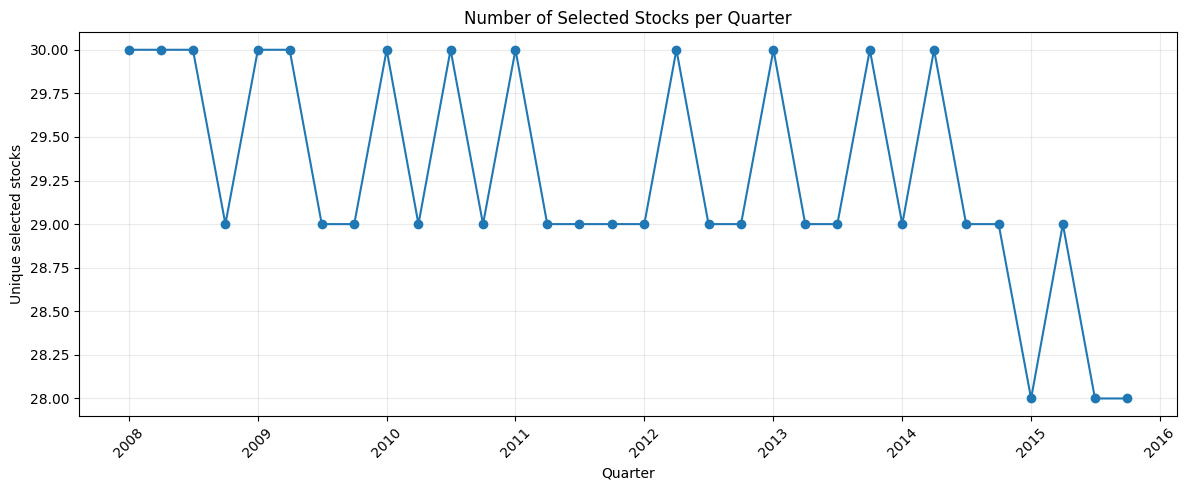

In [7]:
membership_by_quarter = (
    universe_membership.groupby("quarter_start")
    .agg(
        selected_stocks=("symbol", "nunique"),
        average_market_cap_proxy=("market_cap_proxy", "mean")
    )
    .reset_index()
)

display(membership_by_quarter)

fig, ax = plt.subplots()
ax.plot(
    membership_by_quarter["quarter_start"],
    membership_by_quarter["selected_stocks"],
    marker="o"
)
ax.set_title("Number of Selected Stocks per Quarter")
ax.set_xlabel("Quarter")
ax.set_ylabel("Unique selected stocks")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Quarterly universe candidates

Candidates are distinct from selected membership. We inspect both tables because the assignment asks us to use the historically available quarterly candidates, including stocks that may now be inactive.

In [8]:
universe_candidates = con.execute("""
    SELECT *
    FROM universe_candidates
    ORDER BY quarter_start, universe_rank
""").fetchdf()

print("Candidate records:", len(universe_candidates))
print("Unique candidate stocks:", universe_candidates["symbol"].nunique())
display(universe_candidates.head(15))

Candidate records: 942
Unique candidate stocks: 30


,quarter_start,quarter_end,selection_date,effective_start,symbol,selection_close,shares_fiscal_date,shares_filing_date,shares_available_date,selection_shares,market_cap_proxy,universe_rank
0,2008-01-01,2008-03-31,2007-12-31,2008-01-02,XOM,93.69000,2007-09-30,2007-11-07,2007-11-08,"5,535,294,118.00000","518,601,705,915.41998",1
1,2008-01-01,2008-03-31,2007-12-31,2008-01-02,POZN,12.00000,2007-09-30,2007-11-05,2007-11-06,"29,555,787,000.00000","354,669,444,000.00000",3
2,2008-01-01,2008-03-31,2007-12-31,2008-01-02,MSFT,35.60000,2007-09-30,2007-10-25,2007-10-26,"9,513,000,000.00000","338,662,800,000.00000",4
3,2008-01-01,2008-03-31,2007-12-31,2008-01-02,PEGY,"35,610.00000",2007-09-30,2007-11-14,2007-11-15,"8,870,000.00000","315,860,700,000.00000",5
4,2008-01-01,2008-03-31,2007-12-31,2008-01-02,CCZ,40.00000,2007-09-30,2007-10-26,2007-10-27,"6,236,000,000.00000","249,440,000,000.00000",7
5,2008-01-01,2008-03-31,2007-12-31,2008-01-02,PG,73.42000,2007-09-30,2007-10-31,2007-11-01,"3,354,200,000.00000","246,265,364,000.00000",8
6,2008-01-01,2008-03-31,2007-12-31,2008-01-02,GE,177.40000,2007-09-30,2007-11-02,2007-11-03,"1,276,875,000.00000","226,517,625,000.00000",9
7,2008-01-01,2008-03-31,2007-12-31,2008-01-02,BRK-B,94.72000,2007-09-30,2007-11-02,2007-11-03,"2,321,051,000.00000","219,849,953,041.05099",10
8,2008-01-01,2008-03-31,2007-12-31,2008-01-02,BRK-A,"141,600.00000",2007-09-30,2007-11-02,2007-11-03,"1,547,000.00000","219,055,200,000.00000",11
9,2008-01-01,2008-03-31,2007-12-31,2008-01-02,CVX,93.33000,2007-09-30,2007-11-06,2007-11-07,"2,124,198,000.00000","198,251,399,340.00000",12


In [9]:
candidate_counts = (
    universe_candidates.groupby("quarter_start")
    .agg(candidate_count=("symbol", "nunique"))
)

selected_counts = (
    universe_membership.groupby("quarter_start")
    .agg(selected_count=("symbol", "nunique"))
)

universe_comparison = candidate_counts.join(selected_counts)
universe_comparison["selection_rate"] = (
    universe_comparison["selected_count"]
    / universe_comparison["candidate_count"]
)

display(universe_comparison)

,candidate_count,selected_count,selection_rate
quarter_start,,,
2008-01-01,30,30,1.00000
2008-04-01,30,30,1.00000
2008-07-01,30,30,1.00000
2008-10-01,29,29,1.00000
2009-01-01,30,30,1.00000
2009-04-01,30,30,1.00000
2009-07-01,29,29,1.00000
2009-10-01,29,29,1.00000
2010-01-01,30,30,1.00000


## 8. Quarterly rebalance audit

In [10]:
universe_rebalances = con.execute("""
    SELECT *
    FROM universe_rebalances
    ORDER BY quarter_start
""").fetchdf()

display(universe_rebalances)

,quarter_start,quarter_end,selection_date,effective_start,positive_quote_candidates,rankable_candidates,selected_count,shortfall,selected_currently_inactive,delivered_members
0,2008-01-01,2008-03-31,2007-12-31,2008-01-02,2048,1821,1821,179,492,30
1,2008-04-01,2008-06-30,2008-03-31,2008-04-01,2063,1833,1833,167,494,30
2,2008-07-01,2008-09-30,2008-06-30,2008-07-01,2076,1849,1849,151,501,30
3,2008-10-01,2008-12-31,2008-09-30,2008-10-01,2091,1862,1862,138,508,29
4,2009-01-01,2009-03-31,2008-12-31,2009-01-02,2095,1868,1868,132,510,30
5,2009-04-01,2009-06-30,2009-03-31,2009-04-01,2093,1870,1870,130,511,30
6,2009-07-01,2009-09-30,2009-06-30,2009-07-01,2091,1866,1866,134,508,29
7,2009-10-01,2009-12-31,2009-09-30,2009-10-01,2108,1876,1876,124,514,29
8,2010-01-01,2010-03-31,2009-12-31,2010-01-04,2131,1893,1893,107,523,30
9,2010-04-01,2010-06-30,2010-03-31,2010-04-01,2150,1903,1903,97,521,29


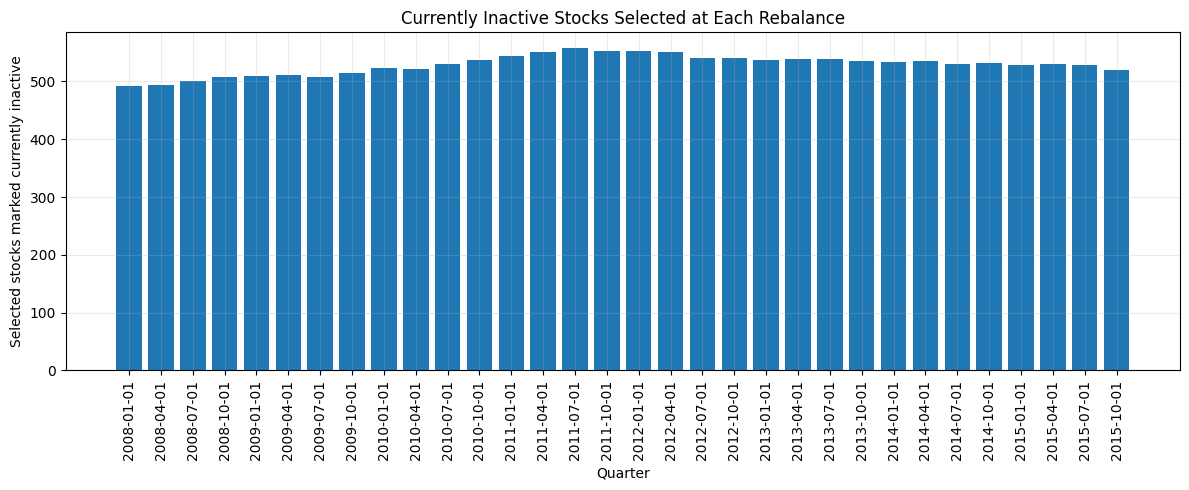

In [11]:
fig, ax = plt.subplots()
ax.bar(
    universe_rebalances["quarter_start"].astype(str),
    universe_rebalances["selected_currently_inactive"]
)
ax.set_title("Currently Inactive Stocks Selected at Each Rebalance")
ax.set_xlabel("Quarter")
ax.set_ylabel("Selected stocks marked currently inactive")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 9. Export all classroom database tables to CSV

The CSV files are written to `Lectures/modeling/outputs/csv_class/`. This directory is ignored by the repository's `.gitignore`.

This cell overwrites existing CSV exports with fresh exports from the DuckDB source.

In [12]:
CSV_DIR = ROOT / "Lectures" / "modeling" / "outputs" / "csv_class"
CSV_DIR.mkdir(parents=True, exist_ok=True)

export_rows = []

for table_name in table_names:
    quoted_table = '"' + table_name.replace('"', '""') + '"'
    csv_path = CSV_DIR / f"{table_name}.csv"

    row_count = con.execute(
        f"SELECT COUNT(*) FROM {quoted_table}"
    ).fetchone()[0]

    sql_path = str(csv_path).replace("'", "''")

    con.execute(
        f"""
        COPY (SELECT * FROM {quoted_table})
        TO '{sql_path}'
        (HEADER, DELIMITER ',')
        """
    )

    export_rows.append({
        "table": table_name,
        "rows": row_count,
        "csv_file": csv_path.name,
        "size_mb": csv_path.stat().st_size / 1024**2
    })

export_summary = (
    pd.DataFrame(export_rows)
    .sort_values("table")
    .reset_index(drop=True)
)

display(export_summary)
print("CSV export directory:", CSV_DIR)

con.close()
print("DuckDB connection closed; Part A continues from the CSV exports.")

,table,rows,csv_file,size_mb
0,benchmark,2015,benchmark.csv,0.07647
1,calendar,2015,calendar.csv,0.02114
2,dataset_metadata,9,dataset_metadata.csv,0.00056
3,dividends,110,dividends.csv,0.00443
4,fundamentals,1059,fundamentals.csv,0.45582
5,prices,59286,prices.csv,3.82841
6,universe,30,universe.csv,0.00299
7,universe_candidates,942,universe_candidates.csv,0.10637
8,universe_membership,937,universe_membership.csv,0.10582
9,universe_rebalances,32,universe_rebalances.csv,0.00226


CSV export directory: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/outputs/csv_class
DuckDB connection closed; Part A continues from the CSV exports.


## 10. Verify CSV exports

In [13]:
csv_files = sorted(CSV_DIR.glob("*.csv"))

for csv_file in csv_files:
    print(
        f"{csv_file.name:35s} "
        f"{csv_file.stat().st_size / 1024:.2f} KB"
    )

print(f"\nTotal CSV files: {len(csv_files)}")

benchmark.csv                       78.30 KB
calendar.csv                        21.65 KB
dataset_metadata.csv                0.57 KB
dividends.csv                       4.54 KB
fundamentals.csv                    466.75 KB
prices.csv                          3920.29 KB
universe.csv                        3.06 KB
universe_candidates.csv             108.93 KB
universe_membership.csv             108.36 KB
universe_rebalances.csv             2.32 KB

Total CSV files: 10


## 11. Load CSVs into Pandas

The database is still the source of truth. These DataFrames are convenient for exploration and feature development.

In [14]:
prices = pd.read_csv(
    CSV_DIR / "prices.csv",
    parse_dates=["date"]
)

fundamentals = pd.read_csv(
    CSV_DIR / "fundamentals.csv",
    parse_dates=["fiscal_date", "filing_date", "period_start"]
)

universe = pd.read_csv(CSV_DIR / "universe.csv")

universe_candidates = pd.read_csv(
    CSV_DIR / "universe_candidates.csv",
    parse_dates=[
        "quarter_start", "quarter_end", "selection_date",
        "effective_start", "shares_fiscal_date",
        "shares_filing_date", "shares_available_date"
    ]
)

universe_membership = pd.read_csv(
    CSV_DIR / "universe_membership.csv",
    parse_dates=[
        "quarter_start", "quarter_end", "selection_date",
        "effective_start", "shares_fiscal_date",
        "shares_filing_date", "shares_available_date"
    ]
)

universe_rebalances = pd.read_csv(
    CSV_DIR / "universe_rebalances.csv",
    parse_dates=["quarter_start", "quarter_end", "selection_date", "effective_start"]
)

benchmark = pd.read_csv(
    CSV_DIR / "benchmark.csv",
    parse_dates=["date"]
)

calendar = pd.read_csv(
    CSV_DIR / "calendar.csv",
    parse_dates=["date"]
)

dividends = pd.read_csv(
    CSV_DIR / "dividends.csv",
    parse_dates=["ex_date", "payment_date"]
)

dataset_metadata = pd.read_csv(CSV_DIR / "dataset_metadata.csv")

for name, df in {
    "prices": prices,
    "fundamentals": fundamentals,
    "universe": universe,
    "universe_candidates": universe_candidates,
    "universe_membership": universe_membership,
    "universe_rebalances": universe_rebalances,
    "benchmark": benchmark,
    "calendar": calendar,
    "dividends": dividends,
}.items():
    print(f"{name:25s} {df.shape}")

prices                    (59286, 9)
fundamentals              (1059, 46)
universe                  (30, 11)
universe_candidates       (942, 12)
universe_membership       (937, 12)
universe_rebalances       (32, 10)
benchmark                 (2015, 5)
calendar                  (2015, 1)
dividends                 (110, 6)


## 12. Structural price-data quality checks

We check for duplicate `(symbol, date)` records, invalid adjusted prices and prices dated outside the provided market calendar. We preserve the source rows and inspect any issues rather than silently deleting them.

In [15]:
prices_raw = prices.copy()

prices_raw["date"] = pd.to_datetime(prices_raw["date"])
prices_raw["adj_close"] = pd.to_numeric(
    prices_raw["adj_close"], errors="coerce"
)

duplicate_mask = prices_raw.duplicated(
    subset=["symbol", "date"],
    keep=False
)

invalid_adj_price_mask = (
    ~np.isfinite(prices_raw["adj_close"])
    | (prices_raw["adj_close"] <= 0)
)

calendar_dates_set = set(calendar["date"])
off_calendar_mask = ~prices_raw["date"].isin(calendar_dates_set)

quality_report = pd.DataFrame({
    "check": [
        "Total price observations",
        "Duplicate symbol-date rows",
        "Invalid adjusted prices",
        "Off-calendar observations",
        "Unique stocks",
        "Unique trading dates"
    ],
    "count": [
        len(prices_raw),
        int(duplicate_mask.sum()),
        int(invalid_adj_price_mask.sum()),
        int(off_calendar_mask.sum()),
        prices_raw["symbol"].nunique(),
        prices_raw["date"].nunique()
    ]
})

display(quality_report)

print("Invalid adjusted-price records:")
display(prices_raw.loc[invalid_adj_price_mask].head(20))

print("Off-calendar records:")
display(prices_raw.loc[off_calendar_mask].head(20))

print("Duplicate records:")
display(prices_raw.loc[duplicate_mask].head(20))

,check,count
0,Total price observations,59286
1,Duplicate symbol-date rows,0
2,Invalid adjusted prices,0
3,Off-calendar observations,0
4,Unique stocks,30
5,Unique trading dates,2015


Invalid adjusted-price records:


,symbol,date,open,high,low,close,adj_close,volume,source


Off-calendar records:


,symbol,date,open,high,low,close,adj_close,volume,source


Duplicate records:


,symbol,date,open,high,low,close,adj_close,volume,source


## 13. Price coverage by stock

A clean price column does not mean every stock has a complete history. We compare observed sessions with the market calendar between each stock's first and last recorded dates.

In [16]:
price_coverage = (
    prices_raw.groupby("symbol")
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        observations=("date", "count"),
        unique_dates=("date", "nunique"),
        missing_adj_close=("adj_close", lambda x: x.isna().sum())
    )
    .reset_index()
)

sorted_calendar = calendar["date"].sort_values()

price_coverage["calendar_sessions"] = price_coverage.apply(
    lambda row: sorted_calendar.between(
        row["first_date"], row["last_date"]
    ).sum(),
    axis=1
)

price_coverage["coverage_pct"] = (
    price_coverage["observations"]
    / price_coverage["calendar_sessions"] * 100
)

display(price_coverage.sort_values("coverage_pct"))

,symbol,first_date,last_date,observations,unique_dates,missing_adj_close,calendar_sessions,coverage_pct
7,CCZ,2008-01-02,2015-12-22,851,851,0,2009,42.35938
0,AAPL,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
2,APDN,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
1,AMT,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
3,BESS,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
4,BKNG,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
5,BRK-A,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
6,BRK-B,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
8,CVX,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000
9,ETR,2008-01-02,2015-12-31,2015,2015,0,2015,100.00000


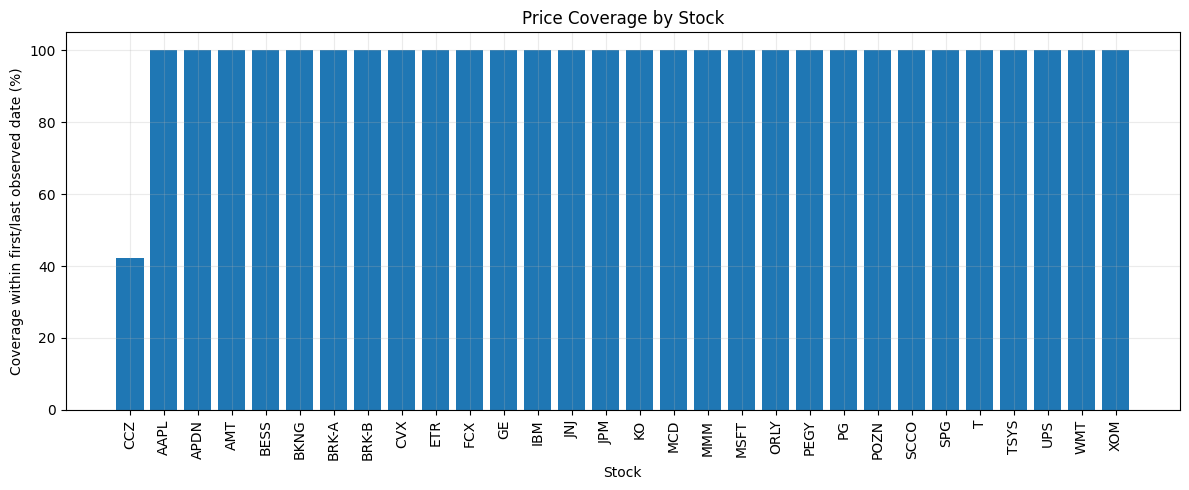

In [17]:
fig, ax = plt.subplots()
plot_coverage = price_coverage.sort_values("coverage_pct")

ax.bar(plot_coverage["symbol"], plot_coverage["coverage_pct"])
ax.set_title("Price Coverage by Stock")
ax.set_xlabel("Stock")
ax.set_ylabel("Coverage within first/last observed date (%)")
ax.set_ylim(0, 105)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 14. Investigate CCZ's missing sessions

CCZ has a substantially lower coverage percentage than the other stocks in the classroom sample. This cell shows whether missing sessions are spread across the years or concentrated in a particular period.

**Do not forward-fill missing prices.** A missing observation must not be turned into an artificial zero return.

In [18]:
ccz = prices_raw.loc[prices_raw["symbol"] == "CCZ"].copy()

if not ccz.empty:
    ccz_calendar = calendar.loc[
        calendar["date"].between(ccz["date"].min(), ccz["date"].max())
    ].copy()

    expected_by_year = (
        ccz_calendar.assign(year=lambda x: x["date"].dt.year)
        .groupby("year")
        .size()
        .rename("expected_sessions")
    )

    observed_by_year = (
        ccz.assign(year=ccz["date"].dt.year)
        .groupby("year")["date"]
        .nunique()
        .rename("observed_sessions")
    )

    ccz_coverage = pd.concat(
        [expected_by_year, observed_by_year], axis=1
    ).fillna(0)

    ccz_coverage["missing_sessions"] = (
        ccz_coverage["expected_sessions"]
        - ccz_coverage["observed_sessions"]
    )

    ccz_coverage["coverage_pct"] = (
        ccz_coverage["observed_sessions"]
        / ccz_coverage["expected_sessions"] * 100
    )

    display(ccz_coverage)
else:
    print("CCZ has no price observations in this database.")

,expected_sessions,observed_sessions,missing_sessions,coverage_pct
year,,,,
2008,253,141,112,55.73123
2009,252,115,137,45.63492
2010,252,159,93,63.09524
2011,252,89,163,35.31746
2012,250,97,153,38.80000
2013,252,84,168,33.33333
2014,252,116,136,46.03175
2015,246,50,196,20.32520


## 15. Preliminary observed-row return scan — diagnostic only

This is a preliminary scan between successive *available rows* for each stock. For a stock with missing trading sessions, this may represent a multi-session return rather than a one-day return.

We therefore do **not** use this scan as the authoritative daily anomaly count. The calendar-aligned daily-return scan in the next section is the correct one for daily diagnostics.

In [19]:
observed_row_prices = prices_raw.sort_values(
    ["symbol", "date"]
).copy()

observed_row_prices["observed_interval_return"] = (
    observed_row_prices.groupby("symbol")["adj_close"].pct_change()
)

preliminary_large_moves = observed_row_prices.loc[
    observed_row_prices["observed_interval_return"].abs() > 0.20
]

print(
    "Observed-row changes exceeding +/-20%:",
    len(preliminary_large_moves)
)
display(
    preliminary_large_moves[
        ["symbol", "date", "adj_close", "observed_interval_return"]
    ].head(30)
)

Observed-row changes exceeding +/-20%: 243


,symbol,date,adj_close,observed_interval_return
2242,AMT,2008-11-24,19.20000,0.20225
4042,APDN,2008-01-18,"4,680,000.45000",0.34021
4047,APDN,2008-01-28,"5,220,000.15000",0.20833
4078,APDN,2008-03-12,"4,320,000.15000",-0.20000
4079,APDN,2008-03-13,"5,400,000.30000",0.25000
4145,APDN,2008-06-17,"4,500,000.30000",0.25000
4167,APDN,2008-07-18,"2,880,000.30000",0.33333
4188,APDN,2008-08-18,"2,356,363.80000",-0.20000
4209,APDN,2008-09-17,"1,440,000.15000",-0.34524
4216,APDN,2008-09-26,"1,956,521.85000",0.21951


## 16. Align prices to the full trading calendar

For each stock, create one row per market session. Missing prices remain missing.

Daily returns are calculated only when the current session and immediately preceding market session both have valid prices. This avoids treating a multi-session gap as a one-day return.

In [20]:
calendar_dates = pd.DatetimeIndex(
    calendar["date"].sort_values(),
    name="date"
)

aligned_frames = []

for symbol, group in prices_raw.groupby("symbol", sort=True):
    stock = (
        group.sort_values("date")
        .set_index("date")
        .reindex(calendar_dates)
    )

    stock["symbol"] = symbol

    stock["prev_close"] = stock["close"].shift(1)
    stock["prev_adj_close"] = stock["adj_close"].shift(1)

    stock["raw_return"] = (
        stock["close"] / stock["prev_close"] - 1
    )

    stock["adj_return"] = (
        stock["adj_close"] / stock["prev_adj_close"] - 1
    )

    stock["adjustment_factor"] = (
        stock["adj_close"] / stock["close"].where(stock["close"] > 0)
    )

    stock["prev_adjustment_factor"] = (
        stock["adjustment_factor"].shift(1)
    )

    stock["adjustment_factor_change"] = (
        stock["adjustment_factor"]
        / stock["prev_adjustment_factor"] - 1
    )

    aligned_frames.append(stock.reset_index())

aligned_prices = pd.concat(
    aligned_frames,
    ignore_index=True
)

print("Calendar-aligned dataset shape:", aligned_prices.shape)
print(
    "Expected rows:",
    prices_raw["symbol"].nunique() * len(calendar_dates)
)
display(aligned_prices.head())

Calendar-aligned dataset shape: (60450, 16)
Expected rows: 60450


,date,symbol,open,high,low,close,adj_close,volume,source,prev_close,prev_adj_close,raw_return,adj_return,adjustment_factor,prev_adjustment_factor,adjustment_factor_change
0,2008-01-02,AAPL,7.12000,7.15000,6.88000,6.96000,5.83000,"1,079,178,800.00000",fmp,NaN,NaN,NaN,NaN,0.83764,NaN,NaN
1,2008-01-03,AAPL,6.98000,7.05000,6.88000,6.96000,5.83000,"842,066,568.00000",fmp,6.96000,5.83000,0.00000,0.00000,0.83764,0.83764,0.00000
2,2008-01-04,AAPL,6.84000,6.89000,6.39000,6.43000,5.39000,"1,455,832,000.00000",fmp,6.96000,5.83000,-0.07615,-0.07547,0.83826,0.83764,0.00073
3,2008-01-07,AAPL,6.47000,6.56000,6.08000,6.34000,5.31000,"2,072,194,711.00000",fmp,6.43000,5.39000,-0.01400,-0.01484,0.83754,0.83826,-0.00086
4,2008-01-08,AAPL,6.43000,6.52000,6.10000,6.12000,5.13000,"1,523,817,072.00000",fmp,6.34000,5.31000,-0.03470,-0.03390,0.83824,0.83754,0.00083


## 17. Calendar-aligned extreme daily movements

We flag adjusted daily returns with absolute value greater than 20%. This is an investigation threshold, **not an automatic deletion rule**.

In [21]:
extreme_summary = (
    aligned_prices.loc[aligned_prices["adj_close"].notna()]
    .groupby("symbol")
    .agg(
        price_observations=("adj_close", "count"),
        valid_daily_returns=("adj_return", "count"),
        extreme_moves=(
            "adj_return",
            lambda x: x.abs().gt(0.20).sum()
        ),
        largest_abs_return=(
            "adj_return",
            lambda x: x.abs().max()
        )
    )
    .reset_index()
    .sort_values("extreme_moves", ascending=False)
)

display(extreme_summary)

,symbol,price_observations,valid_daily_returns,extreme_moves,largest_abs_return
3,BESS,2015,2014,141,4.00000
2,APDN,2015,2014,70,0.60827
20,PEGY,2015,2014,7,1.26402
14,JPM,2015,2014,5,0.25082
22,POZN,2015,2014,4,0.44800
26,TSYS,2015,2014,4,0.31099
24,SPG,2015,2014,3,0.25402
4,BKNG,2015,2014,2,0.21950
23,SCCO,2015,2014,2,0.28988
10,FCX,2015,2014,2,0.28611


## 18. Detailed anomaly investigation: BESS, APDN and PEGY

These symbols showed many extreme movements in the classroom data. We compare raw returns, adjusted returns, adjustment factors and volume.

The code displays a limited number of observations per stock to keep notebook output manageable. The full source data remains available in `aligned_prices`.

In [22]:
focus_symbols = ["BESS", "APDN", "PEGY"]

for symbol in focus_symbols:
    print(f"\n{'=' * 75}")
    print(f"ANOMALY INVESTIGATION: {symbol}")
    print(f"{'=' * 75}")

    stock = aligned_prices.loc[
        aligned_prices["symbol"] == symbol
    ].copy()

    stock["abs_adj_return"] = stock["adj_return"].abs()

    events = stock.loc[
        stock["abs_adj_return"] > 0.20,
        [
            "date", "close", "prev_close", "raw_return",
            "adj_close", "prev_adj_close", "adj_return",
            "adjustment_factor", "adjustment_factor_change",
            "volume", "abs_adj_return"
        ]
    ].sort_values("abs_adj_return", ascending=False)

    print(f"Extreme daily observations: {len(events)}")
    display(events.head(30))


ANOMALY INVESTIGATION: BESS
Extreme daily observations: 141


,date,close,prev_close,raw_return,adj_close,prev_adj_close,adj_return,adjustment_factor,adjustment_factor_change,volume,abs_adj_return
6298,2009-01-02,70.00000,14.00000,4.00000,70.00000,14.00000,4.00000,1.00000,0.00000,964.00000,4.00000
6516,2009-11-12,140.00000,50.40000,1.77778,140.00000,50.40000,1.77778,1.00000,0.00000,115.00000,1.77778
6270,2008-11-20,23.80000,11.20000,1.12500,23.80000,11.20000,1.12500,1.00000,0.00000,104.00000,1.12500
6340,2009-03-05,70.00000,35.00000,1.00000,70.00000,35.00000,1.00000,1.00000,0.00000,250.00000,1.00000
6269,2008-11-19,11.20000,5.60000,1.00000,11.20000,5.60000,1.00000,1.00000,0.00000,"1,214.00000",1.00000
6217,2008-09-08,68.60000,35.00000,0.96000,68.60000,35.00000,0.96000,1.00000,0.00000,1.00000,0.96000
6291,2008-12-22,35.00000,18.20000,0.92308,35.00000,18.20000,0.92308,1.00000,0.00000,319.00000,0.92308
6206,2008-08-21,67.20000,35.00000,0.92000,67.20000,35.00000,0.92000,1.00000,0.00000,258.00000,0.92000
6271,2008-11-21,42.00000,23.80000,0.76471,42.00000,23.80000,0.76471,1.00000,0.00000,471.00000,0.76471
6295,2008-12-29,8.40000,35.00000,-0.76000,8.40000,35.00000,-0.76000,1.00000,0.00000,554.00000,0.76000



ANOMALY INVESTIGATION: APDN
Extreme daily observations: 70


,date,close,prev_close,raw_return,adj_close,prev_adj_close,adj_return,adjustment_factor,adjustment_factor_change,volume,abs_adj_return
5197,2012-08-17,"3,966,000.00000","2,466,000.00000",0.60827,"3,966,000.00000","2,466,000.00000",0.60827,1.00000,0.00000,0.00000,0.60827
4771,2010-12-09,"2,519,999.85000","1,620,000.00000",0.55556,"2,519,999.85000","1,620,000.00000",0.55556,1.00000,0.00000,0.00000,0.55556
6001,2015-10-29,"1,920,000.00000","4,218,000.00000",-0.54481,"1,920,000.00000","4,218,000.00000",-0.54481,1.00000,0.00000,20.00000,0.54481
4354,2009-04-16,"4,680,000.45000","3,384,000.15000",0.38298,"4,680,000.45000","3,384,000.15000",0.38298,1.00000,0.00000,0.00000,0.38298
4325,2009-03-05,"2,304,000.15000","3,600,000.30000",-0.36000,"2,304,000.15000","3,600,000.30000",-0.36000,1.00000,0.00000,0.00000,0.36000
4209,2008-09-17,"1,440,000.15000","2,199,272.85000",-0.34524,"1,440,000.15000","2,199,272.85000",-0.34524,1.00000,0.00000,0.00000,0.34524
4042,2008-01-18,"4,680,000.45000","3,492,000.30000",0.34021,"4,680,000.45000","3,492,000.30000",0.34021,1.00000,0.00000,0.00000,0.34021
4693,2010-08-19,"1,440,000.15000","1,080,000.00000",0.33333,"1,440,000.15000","1,080,000.00000",0.33333,1.00000,0.00000,0.00000,0.33333
4229,2008-10-15,"1,645,714.50000","1,234,285.80000",0.33333,"1,645,714.50000","1,234,285.80000",0.33333,1.00000,0.00000,0.00000,0.33333
4225,2008-10-09,"1,645,714.50000","1,234,285.80000",0.33333,"1,645,714.50000","1,234,285.80000",0.33333,1.00000,0.00000,0.00000,0.33333



ANOMALY INVESTIGATION: PEGY
Extreme daily observations: 7


,date,close,prev_close,raw_return,adj_close,prev_adj_close,adj_return,adjustment_factor,adjustment_factor_change,volume,abs_adj_return
40461,2008-08-21,"32,520.00000","32,520.00000",0.00000,"24,220.59000","10,698.04000",1.26402,0.74479,1.26402,0.00000,1.26402
40642,2009-05-12,"28,080.00000","28,080.00000",0.00000,"20,932.31000","9,660.16000",1.16687,0.74545,1.16687,0.00000,1.16687
42257,2015-10-09,"25,560.00000","25,560.00000",0.00000,"22,873.09000","12,383.95000",0.84699,0.89488,0.84699,0.00000,0.84699
40462,2008-08-22,"32,520.00000","32,520.00000",0.00000,"10,698.04000","24,220.59000",-0.55831,0.32897,-0.55831,2.00000,0.55831
40643,2009-05-13,"27,300.00000","28,080.00000",-0.02778,"9,391.82000","20,932.31000",-0.55132,0.34402,-0.53850,1.00000,0.55132
42258,2015-10-12,"24,930.00000","25,560.00000",-0.02465,"12,078.71000","22,873.09000",-0.47192,0.48451,-0.45858,3.00000,0.47192
40574,2009-02-03,"27,180.00000","22,518.00000",0.20703,"9,194.70000","7,617.60000",0.20703,0.33829,-0.00000,4.00000,0.20703


## 19. Adjustment-factor discontinuities

The adjustment factor is `adj_close / close`. Large changes may be associated with corporate actions or data inconsistencies. They are clues for investigation, not proof of an error.

In [23]:
factor_events = aligned_prices.loc[
    aligned_prices["adjustment_factor_change"].abs() > 0.05,
    [
        "symbol", "date", "close", "adj_close",
        "adjustment_factor", "adjustment_factor_change",
        "raw_return", "adj_return"
    ]
].copy()

factor_events["abs_factor_change"] = (
    factor_events["adjustment_factor_change"].abs()
)

factor_events = factor_events.sort_values(
    "abs_factor_change", ascending=False
)

print("Adjustment-factor changes greater than 5%:", len(factor_events))
display(factor_events.head(50))

Adjustment-factor changes greater than 5%: 7


,symbol,date,close,adj_close,adjustment_factor,adjustment_factor_change,raw_return,adj_return,abs_factor_change
40461,PEGY,2008-08-21,"32,520.00000","24,220.59000",0.74479,1.26402,0.00000,1.26402,1.26402
40642,PEGY,2009-05-12,"28,080.00000","20,932.31000",0.74545,1.16687,0.00000,1.16687,1.16687
42257,PEGY,2015-10-09,"25,560.00000","22,873.09000",0.89488,0.84699,0.00000,0.84699,0.84699
40462,PEGY,2008-08-22,"32,520.00000","10,698.04000",0.32897,-0.55831,0.00000,-0.55831,0.55831
40643,PEGY,2009-05-13,"27,300.00000","9,391.82000",0.34402,-0.53850,-0.02778,-0.55132,0.53850
42258,PEGY,2015-10-12,"24,930.00000","12,078.71000",0.48451,-0.45858,-0.02465,-0.47192,0.45858
47566,SCCO,2012-11-06,34.77000,23.93000,0.68824,0.07668,-0.08234,-0.01197,0.07668


## 20. Volume diagnostics

Zero or very low reported volume can be a warning sign. It is not, by itself, proof that a price observation is invalid.

In [24]:
volume_summary = (
    prices_raw.groupby("symbol")
    .agg(
        mean_volume=("volume", "mean"),
        median_volume=("volume", "median"),
        zero_volume_days=("volume", lambda x: x.eq(0).sum()),
        missing_volume_days=("volume", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(
    volume_summary.loc[
        volume_summary["symbol"].isin(focus_symbols)
    ]
)

,symbol,mean_volume,median_volume,zero_volume_days,missing_volume_days
2,APDN,0.04814,0.00000,1964,0
3,BESS,125.84367,51.00000,434,0
20,PEGY,5.24417,3.00000,3,0


## 21. Data-quality observations and provisional handling policy

The classroom data inspection so far found:
- 30 securities in the classroom universe.
- 26 marked active and 4 marked inactive in the snapshot metadata.
- 59,286 source price observations across 2,015 trading dates.
- No duplicate `(symbol, date)` rows in the initial structural audit.
- No non-finite or non-positive adjusted prices in the initial structural audit.
- No price dates outside the supplied trading calendar.
- CCZ has materially incomplete price coverage.
- BESS has many extreme calendar-aligned daily moves and low reported volume.
- APDN has implausibly large nominal prices and predominantly zero reported volume.
- PEGY has large adjustment-factor discontinuities in several observations.

**Provisional policy**
1. Preserve original source observations.
2. Do not automatically delete extreme returns.
3. Do not forward-fill missing prices.
4. Do not manually reapply split or dividend adjustments to `adj_close`.
5. Investigate suspicious observations and document unresolved issues.
6. Any investability filter in the final experiment must use information available at the prediction time.
7. Do not exclude stocks because they are currently inactive.

These observations describe the classroom data only; the same diagnostics apply unchanged to the full homework database.

## 22. Return and risk feature engineering

We now construct daily returns and rolling volatility using adjusted closing prices.

- Simple returns are useful for portfolio accounting.
- Log returns are useful for time-series analysis and volatility estimation.
- Realized volatility is calculated using complete trailing windows of daily log returns.
- Prices and returns are not forward-filled.

For daily annualization, we use 252 trading sessions.

### 22.1 `add_simple_returns()`

$$
R_t = \frac{P_t}{P_{t-1}} - 1
$$

In [25]:
def add_simple_returns(
    df,
    price_col="adj_close",
    group_col="symbol",
    date_col="date"
):
    """Calculate one-session simple returns separately for each stock.

    A return is missing if either the current or immediately previous
    calendar-session price is missing or non-positive. No forward-fill
    is performed.
    """
    result = df.sort_values(
        [group_col, date_col]
    ).reset_index(drop=True).copy()

    current = pd.to_numeric(result[price_col], errors="coerce")
    previous = current.groupby(
        result[group_col], sort=False
    ).shift(1)

    valid = (
        current.notna()
        & previous.notna()
        & current.gt(0)
        & previous.gt(0)
        & np.isfinite(current)
        & np.isfinite(previous)
    )

    result["simple_return"] = (
        current.div(previous).where(valid) - 1
    )

    return result

### 22.2 `add_log_returns()`

$$
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
$$

In [26]:
def add_log_returns(
    df,
    price_col="adj_close",
    group_col="symbol",
    date_col="date"
):
    """Calculate one-session log returns separately for each stock.

    A return is missing if either the current or immediately previous
    calendar-session price is missing or non-positive. No forward-fill
    is performed.
    """
    result = df.sort_values(
        [group_col, date_col]
    ).reset_index(drop=True).copy()

    current = pd.to_numeric(result[price_col], errors="coerce")
    previous = current.groupby(
        result[group_col], sort=False
    ).shift(1)

    valid = (
        current.notna()
        & previous.notna()
        & current.gt(0)
        & previous.gt(0)
        & np.isfinite(current)
        & np.isfinite(previous)
    )

    ratio = current.div(previous).where(valid)
    result["log_return"] = np.log(ratio)

    return result

### 22.3 `add_realized_vol()`

$$
\sigma_{n,t} =
\operatorname{Std}(r_{t-n+1},\ldots,r_t)\sqrt{252}
$$

We use the sample standard deviation (`ddof=1`) and require a complete window of observed daily returns.

In [27]:
def add_realized_vol(
    df,
    window=20,
    return_col="log_return",
    group_col="symbol",
    date_col="date",
    annualization=252
):
    """Calculate annualized rolling volatility by stock.

    The rolling window requires `window` non-missing daily returns.
    Missing sessions are not filled.
    """
    if window <= 1:
        raise ValueError("window must be greater than 1")
    if annualization <= 0:
        raise ValueError("annualization must be positive")
    if return_col not in df.columns:
        raise KeyError(f"Missing return column: {return_col}")

    result = df.sort_values(
        [group_col, date_col]
    ).reset_index(drop=True).copy()

    output_col = f"realized_vol_{window}"

    result[output_col] = (
        result.groupby(group_col, sort=False)[return_col]
        .transform(
            lambda series: (
                series.rolling(
                    window=window,
                    min_periods=window
                ).std(ddof=1) * np.sqrt(annualization)
            )
        )
    )

    return result

## 23. Apply return and volatility functions

We use the calendar-aligned data. Because missing dates remain explicit rows, a return after a missing session is not treated as a one-day return.

In [28]:
price_features = aligned_prices[
    ["date", "symbol", "close", "adj_close", "volume"]
].copy()

price_features = add_simple_returns(price_features)
price_features = add_log_returns(price_features)

price_features = add_realized_vol(
    price_features,
    window=20
)

price_features = add_realized_vol(
    price_features,
    window=63
)

print("Feature dataset shape:", price_features.shape)

display(
    price_features.loc[
        price_features["symbol"] == "AAPL"
    ].head(25)
)

Feature dataset shape: (60450, 9)


,date,symbol,close,adj_close,volume,simple_return,log_return,realized_vol_20,realized_vol_63
0,2008-01-02,AAPL,6.96000,5.83000,"1,079,178,800.00000",NaN,NaN,NaN,NaN
1,2008-01-03,AAPL,6.96000,5.83000,"842,066,568.00000",0.00000,0.00000,NaN,NaN
2,2008-01-04,AAPL,6.43000,5.39000,"1,455,832,000.00000",-0.07547,-0.07847,NaN,NaN
3,2008-01-07,AAPL,6.34000,5.31000,"2,072,194,711.00000",-0.01484,-0.01495,NaN,NaN
4,2008-01-08,AAPL,6.12000,5.13000,"1,523,817,072.00000",-0.03390,-0.03449,NaN,NaN
5,2008-01-09,AAPL,6.41000,5.37000,"1,815,540,628.00000",0.04678,0.04572,NaN,NaN
6,2008-01-10,AAPL,6.36000,5.33000,"1,482,975,200.00000",-0.00745,-0.00748,NaN,NaN
7,2008-01-11,AAPL,6.17000,5.17000,"1,232,285,600.00000",-0.03002,-0.03048,NaN,NaN
8,2008-01-14,AAPL,6.38000,5.35000,"1,100,450,828.00000",0.03482,0.03422,NaN,NaN
9,2008-01-15,AAPL,6.04000,5.06000,"2,350,264,556.00000",-0.05421,-0.05573,NaN,NaN


## 24. Validate return calculations

We check:
1. Log returns equal `log1p(simple_return)` wherever simple returns are valid.
2. The first observation for each stock has missing returns.
3. No infinite return values are generated.

In [29]:
valid_simple = price_features["simple_return"].notna()

expected_log = np.log1p(
    price_features.loc[valid_simple, "simple_return"]
)

assert np.allclose(
    price_features.loc[valid_simple, "log_return"],
    expected_log,
    rtol=1e-10,
    atol=1e-12
)

first_rows = (
    price_features.sort_values(["symbol", "date"])
    .groupby("symbol", sort=False)
    .head(1)
)

assert first_rows["simple_return"].isna().all()
assert first_rows["log_return"].isna().all()

assert np.isfinite(
    price_features["simple_return"].dropna()
).all()

assert np.isfinite(
    price_features["log_return"].dropna()
).all()

print("All simple-return and log-return validation checks passed.")

All simple-return and log-return validation checks passed.


## 25. Inspect the first available volatility values

For a stock with a complete daily price history:
- The first daily return is missing because there is no prior session.
- A 20-return volatility estimate first becomes available after 20 valid returns.
- A 63-return volatility estimate first becomes available after 63 valid returns.

Therefore the first volatility values appear later than the first price and return observations.

In [30]:
aapl = (
    price_features.loc[price_features["symbol"] == "AAPL"]
    .sort_values("date")
    .reset_index(drop=True)
)

print("20-day volatility around first available value:")
display(
    aapl.loc[
        aapl["realized_vol_20"].notna()
    ].head(5)[
        ["date", "adj_close", "log_return", "realized_vol_20"]
    ]
)

print("63-day volatility around first available value:")
display(
    aapl.loc[
        aapl["realized_vol_63"].notna()
    ].head(5)[
        ["date", "adj_close", "log_return", "realized_vol_63"]
    ]
)

20-day volatility around first available value:


,date,adj_close,log_return,realized_vol_20
20,2008-01-31,4.05000,0.02247,0.61446
21,2008-02-01,4.01000,-0.00993,0.61156
22,2008-02-04,3.94000,-0.01761,0.56938
23,2008-02-05,3.87000,-0.01793,0.56943
24,2008-02-06,3.65000,-0.05853,0.58604


63-day volatility around first available value:


,date,adj_close,log_return,realized_vol_63
63,2008-04-03,4.54000,0.02679,0.52414
64,2008-04-04,4.59000,0.01095,0.52494
65,2008-04-07,4.67000,0.01728,0.50409
66,2008-04-08,4.58000,-0.01946,0.50463
67,2008-04-09,4.54000,-0.00877,0.50058


## 26. Feature availability by stock

In [31]:
feature_availability = (
    price_features.groupby("symbol")
    .agg(
        total_sessions=("date", "count"),
        valid_prices=("adj_close", "count"),
        valid_simple_returns=("simple_return", "count"),
        valid_log_returns=("log_return", "count"),
        valid_vol_20=("realized_vol_20", "count"),
        valid_vol_63=("realized_vol_63", "count")
    )
    .reset_index()
)

feature_availability["vol_63_coverage_pct"] = (
    feature_availability["valid_vol_63"]
    / feature_availability["total_sessions"] * 100
)

display(
    feature_availability.sort_values("vol_63_coverage_pct")
)

,symbol,total_sessions,valid_prices,valid_simple_returns,valid_log_returns,valid_vol_20,valid_vol_63,vol_63_coverage_pct
7,CCZ,2015,851,480,480,15,0,0.00000
0,AAPL,2015,2015,2014,2014,1995,1952,96.87345
2,APDN,2015,2015,2014,2014,1995,1952,96.87345
1,AMT,2015,2015,2014,2014,1995,1952,96.87345
3,BESS,2015,2015,2014,2014,1995,1952,96.87345
4,BKNG,2015,2015,2014,2014,1995,1952,96.87345
5,BRK-A,2015,2015,2014,2014,1995,1952,96.87345
6,BRK-B,2015,2015,2014,2014,1995,1952,96.87345
8,CVX,2015,2015,2014,2014,1995,1952,96.87345
9,ETR,2015,2015,2014,2014,1995,1952,96.87345


## 27. Visualize adjusted price and realized volatility

The following plots are descriptive diagnostics, not investment recommendations.

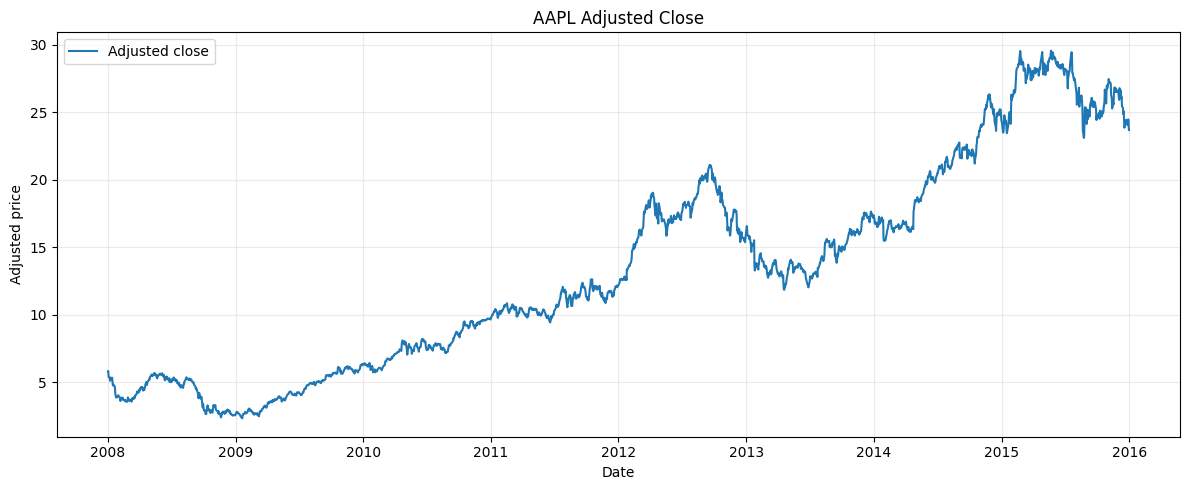

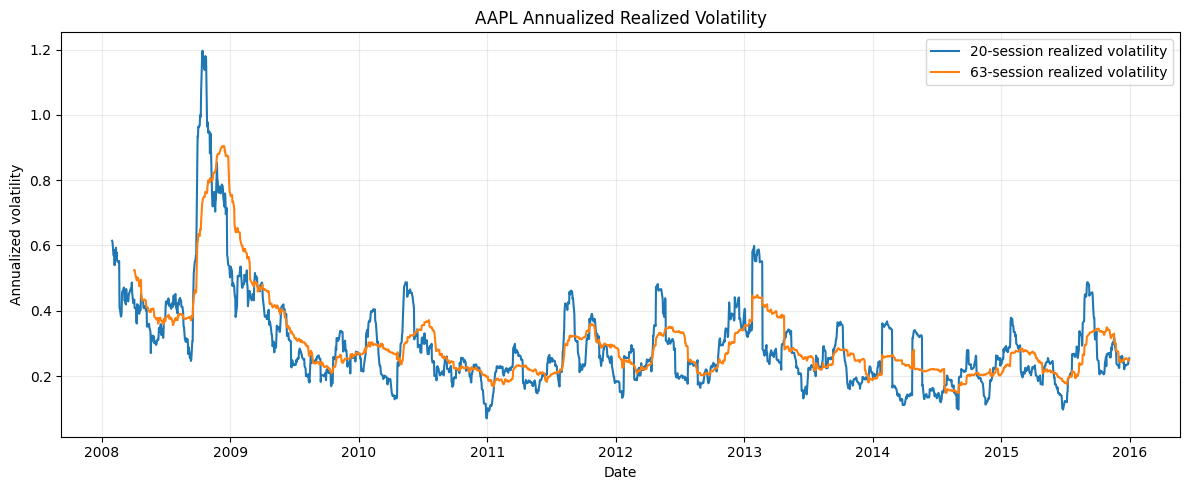

In [32]:
fig, ax = plt.subplots()
ax.plot(aapl["date"], aapl["adj_close"], label="Adjusted close")
ax.set_title("AAPL Adjusted Close")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted price")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(
    aapl["date"],
    aapl["realized_vol_20"],
    label="20-session realized volatility"
)
ax.plot(
    aapl["date"],
    aapl["realized_vol_63"],
    label="63-session realized volatility"
)
ax.set_title("AAPL Annualized Realized Volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.legend()
plt.tight_layout()
plt.show()

# Part B — Strategy Development and Validation

## 28. Development configuration

The validation years, label rules and portfolio construction assumptions are defined here, before any model comparison, and are not changed afterwards.

In [33]:
DEV_START = pd.Timestamp("2010-01-01")
DEV_END = pd.Timestamp("2015-12-31")

VALIDATION_YEARS = [2013, 2014, 2015]

HOLDING_DAYS = 90
MAX_EXIT_DELAY_SESSIONS = 5

# Training targets are winsorized at these quantiles of each training fold.
# Validation metrics and cohort diagnostics always use the raw target.
TARGET_CLIP_QUANTILES = (0.01, 0.99)

GROWTH_SLEEVE_SHARE = 0.50
DEFENSIVE_SLEEVE_SHARE = 0.50
DEFENSIVE_VOLATILITY_QUANTILE = 0.40

MAX_POSITION_WEIGHT = 0.10
MAX_SECTOR_WEIGHT = 0.20

ANNUALIZATION = 252

assert GROWTH_SLEEVE_SHARE + DEFENSIVE_SLEEVE_SHARE == 1.0
assert MAX_POSITION_WEIGHT > 0
assert MAX_SECTOR_WEIGHT > 0
assert 0 <= TARGET_CLIP_QUANTILES[0] < TARGET_CLIP_QUANTILES[1] <= 1

STRATEGY_CONFIG = {
    "development_database": "equities_class.duckdb",
    "development_start": str(DEV_START.date()),
    "development_end": str(DEV_END.date()),
    "validation_years": VALIDATION_YEARS,
    "holding_days_calendar": HOLDING_DAYS,
    "max_exit_delay_sessions": MAX_EXIT_DELAY_SESSIONS,
    "signal_schedule": "last supplied market session of each month",
    "entry_rule": "next supplied market session close",
    "refit_schedule": (
        "once per calendar year, before that year's first signal, using only "
        "labels whose label_end is strictly before that signal"
    ),
    "training_target_clip_quantiles": list(TARGET_CLIP_QUANTILES),
    "growth_sleeve_share": GROWTH_SLEEVE_SHARE,
    "defensive_sleeve_share": DEFENSIVE_SLEEVE_SHARE,
    "defensive_volatility_quantile_within_sector": DEFENSIVE_VOLATILITY_QUANTILE,
    "max_position_weight": MAX_POSITION_WEIGHT,
    "max_sector_weight": MAX_SECTOR_WEIGHT,
    "sector_use": "current snapshot sector used only for portfolio grouping, not as a model feature",
}
display(pd.Series(STRATEGY_CONFIG, name="value").to_frame())

,value
development_database,equities_class.duckdb
development_start,2010-01-01
development_end,2015-12-31
validation_years,"[2013, 2014, 2015]"
holding_days_calendar,90
max_exit_delay_sessions,5
signal_schedule,last supplied market session of each month
entry_rule,next supplied market session close
refit_schedule,"once per calendar year, before that year's fir..."
training_target_clip_quantiles,"[0.01, 0.99]"


## 29. Build the labeled research panel

`prepare_panel` performs the course-defined workflow:
- reads the classroom data;
- constructs historical price features on the supplied market calendar without filling missing prices;
- creates financial events using filing date plus one calendar day;
- joins financial events backward as-of the feature date;
- attaches quarterly membership for the quarter of the next-session entry;
- creates the next-session entry and 90-calendar-day exit target.

The resulting panel contains the historical feature row, membership eligibility, entry/exit audit dates and the realized target. Future label columns must never be included in `FEATURE_COLUMNS`.

In [34]:
panel = prepare_panel(
    database=CLASS_DB,
    end=str(DEV_END.date())
)

for col in [
    "date", "fiscal_date", "filing_date", "available_date",
    "universe_selection_date", "entry_date", "scheduled_exit", "label_end"
]:
    if col in panel.columns:
        panel[col] = pd.to_datetime(panel[col], errors="coerce")

panel = panel.sort_values(["date", "symbol"]).reset_index(drop=True)

print("Panel shape:", panel.shape)
print("Unique symbols:", panel["symbol"].nunique())
print("Date range:", panel["date"].min(), "to", panel["date"].max())
print("Columns:", panel.columns.tolist())

display(panel.head())

Panel shape: (59286, 33)
Unique symbols: 30
Date range: 2008-01-02 00:00:00 to 2015-12-31 00:00:00
Columns: ['date', 'symbol', 'close', 'adj_close', 'volume', 'momentum_21', 'momentum_63', 'momentum_252_21', 'volatility_63', 'drawdown_252', 'eligible', 'fiscal_date', 'filing_date', 'available_date', 'net_margin', 'operating_roa', 'debt_to_assets', 'cash_to_assets', 'fcf_to_assets', 'accruals_to_assets', 'filing_age_days', 'sector', 'membership_quarter', 'quarter_end', 'universe_selection_date', 'universe_rank', 'is_universe_member', 'entry_date', 'entry_price', 'scheduled_exit', 'label_end', 'exit_price', 'target']


,date,symbol,close,adj_close,volume,momentum_21,momentum_63,momentum_252_21,volatility_63,drawdown_252,eligible,fiscal_date,filing_date,available_date,net_margin,operating_roa,debt_to_assets,cash_to_assets,fcf_to_assets,accruals_to_assets,filing_age_days,sector,membership_quarter,quarter_end,universe_selection_date,universe_rank,is_universe_member,entry_date,entry_price,scheduled_exit,label_end,exit_price,target
0,2008-01-02,AAPL,6.96000,5.83000,"1,079,178,800.00000",NaN,NaN,NaN,NaN,NaN,False,2007-09-29,2007-11-15,2007-11-16,0.14541,0.04182,0.00000,0.36896,0.05768,-0.03125,47,Technology,2008-01-01,2008-03-31,2007-12-31,17.00000,True,2008-01-03,5.83000,2008-04-02,2008-04-02,4.42000,-0.24185
1,2008-01-02,AMT,41.24000,31.49000,"3,144,900.00000",NaN,NaN,NaN,NaN,NaN,False,2007-09-30,2007-11-09,2007-11-10,0.16222,0.01201,0.49088,0.01009,0.01734,-0.01487,53,Real Estate,2008-01-01,2008-03-31,2007-12-31,167.00000,True,2008-01-03,30.89000,2008-04-02,2008-04-02,30.79000,-0.00324
2,2008-01-02,APDN,"3,492,000.30000","3,492,000.30000",0.00000,NaN,NaN,NaN,NaN,NaN,False,2007-03-31,2007-05-21,2007-05-22,NaN,-0.86862,5.58992,0.03627,-0.22922,-3.57988,225,Healthcare,2008-01-01,2008-03-31,2007-12-31,16.00000,True,2008-01-03,"3,600,000.30000",2008-04-02,2008-04-02,"4,320,000.15000",0.20000
3,2008-01-02,BESS,369.60000,369.60000,29.00000,NaN,NaN,NaN,NaN,NaN,False,2007-09-30,2007-11-19,2007-11-20,NaN,-13.35571,2.52650,0.25793,-1.12854,-12.22716,43,Utilities,2008-01-01,2008-03-31,2007-12-31,121.00000,True,2008-01-03,378.00000,2008-04-02,2008-04-02,385.00000,0.01852
4,2008-01-02,BKNG,115.24000,114.42000,"1,619,800.00000",NaN,NaN,NaN,NaN,NaN,False,2007-09-30,2007-11-09,2007-11-10,0.25010,0.05697,0.41544,0.30897,0.04099,0.03114,53,Consumer Cyclical,2008-01-01,2008-03-31,2007-12-31,27.00000,True,2008-01-03,110.60000,2008-04-02,2008-04-02,126.59000,0.14458


## 30. Enforce the five-session exit-delay rule

The strategy allows the exit to occur at most five market sessions after the first session on or after the scheduled 90-calendar-day maturity. We measure that delay for every label on the supplied market calendar:

$$
\text{delay} = \operatorname{pos}(\text{label\_end}) - \operatorname{pos}(\text{first session} \ge \text{scheduled\_exit})
$$

A delay of 0 means the position exits on the first session on or after maturity. Any label with a delay above `MAX_EXIT_DELAY_SESSIONS` is set to missing, so it is neither trained on nor scored, and no fill is invented.

In [35]:
session_array = np.sort(
    pd.to_datetime(calendar["date"]).unique()
).astype("datetime64[ns]")

has_exit = panel["label_end"].notna() & panel["scheduled_exit"].notna()

first_session_on_or_after_maturity = np.searchsorted(
    session_array,
    panel.loc[has_exit, "scheduled_exit"].values.astype("datetime64[ns]"),
    side="left"
)
label_end_position = np.searchsorted(
    session_array,
    panel.loc[has_exit, "label_end"].values.astype("datetime64[ns]"),
    side="left"
)

panel["exit_delay_sessions"] = np.nan
panel.loc[has_exit, "exit_delay_sessions"] = (
    label_end_position - first_session_on_or_after_maturity
)

late_exit = panel["exit_delay_sessions"].gt(MAX_EXIT_DELAY_SESSIONS)
LABELS_VOIDED_BY_EXIT_RULE = int((late_exit & panel["target"].notna()).sum())

print("Exit delay in market sessions (rows with an observed exit):")
display(
    panel.loc[has_exit, "exit_delay_sessions"]
    .astype(int)
    .value_counts()
    .sort_index()
    .rename_axis("exit_delay_sessions")
    .to_frame("rows")
)

panel.loc[late_exit, ["target", "exit_price"]] = np.nan

print(
    f"Labels set to missing because exit delay > {MAX_EXIT_DELAY_SESSIONS} sessions:",
    LABELS_VOIDED_BY_EXIT_RULE
)

Exit delay in market sessions (rows with an observed exit):


,rows
exit_delay_sessions,
0,56839
1,78
2,38
3,31
4,30
5,20


Labels set to missing because exit delay > 5 sessions: 0


## 31. Audit feature and label timing

In [36]:
required_columns = (
    FEATURE_COLUMNS
    + [
        "date", "symbol", "sector", "eligible", "is_universe_member",
        "universe_selection_date", "available_date",
        "entry_date", "entry_price", "scheduled_exit",
        "label_end", "exit_price", "target"
    ]
)

missing_required = [c for c in required_columns if c not in panel.columns]
if missing_required:
    raise KeyError(f"Missing expected panel columns: {missing_required}")

# No future label or audit field may be used as a model feature.
label_columns = {
    "target", "entry_date", "entry_price", "scheduled_exit",
    "label_end", "exit_price", "exit_delay_sessions"
}
assert not label_columns.intersection(FEATURE_COLUMNS)

# One feature row per stock and signal date.
assert not panel.duplicated(["symbol", "date"]).any()

# No financial feature may be used before its availability date.
available_mask = panel["available_date"].notna()
assert (
    panel.loc[available_mask, "available_date"]
    <= panel.loc[available_mask, "date"]
).all()

# Membership must have been selected by the signal-date close.
member_mask = panel["is_universe_member"].fillna(False).astype(bool)
assert (
    panel.loc[member_mask, "universe_selection_date"]
    <= panel.loc[member_mask, "date"]
).all()

# Every non-missing target must have a valid entry and exit audit trail.
label_mask = panel["target"].notna()
assert panel.loc[label_mask, "entry_date"].notna().all()
assert panel.loc[label_mask, "label_end"].notna().all()
assert (panel.loc[label_mask, "entry_date"] > panel.loc[label_mask, "date"]).all()
assert panel.loc[label_mask, "entry_price"].gt(0).all()
assert panel.loc[label_mask, "exit_price"].gt(0).all()
assert (
    panel.loc[label_mask, "label_end"]
    >= panel.loc[label_mask, "scheduled_exit"]
).all()

# Exit delay must respect the strategy's quote-delay limit.
assert panel.loc[label_mask, "exit_delay_sessions"].between(
    0, MAX_EXIT_DELAY_SESSIONS
).all()

# Independently recalculate target.
recalculated_target = (
    panel.loc[label_mask, "exit_price"]
    / panel.loc[label_mask, "entry_price"] - 1
)
assert np.allclose(
    panel.loc[label_mask, "target"],
    recalculated_target,
    rtol=1e-10,
    atol=1e-12
)

print("Feature timing, membership timing, exit-delay and target arithmetic checks passed.")

Feature timing, membership timing, exit-delay and target arithmetic checks passed.


In [37]:
eligible_flag = panel["eligible"].fillna(False).astype(bool)
member_flag = panel["is_universe_member"].fillna(False).astype(bool)

audit_checks = [
    ("Total panel rows", len(panel)),
    ("Unique symbols", panel["symbol"].nunique()),
    ("Eligible and member rows", int((eligible_flag & member_flag).sum())),
    ("Rows with completed 90-day targets", int(panel["target"].notna().sum())),
    ("Rows with missing targets", int(panel["target"].isna().sum())),
    ("Labels voided by the exit-delay rule", LABELS_VOIDED_BY_EXIT_RULE),
    ("Rows with an available fundamental record", int(panel["available_date"].notna().sum())),
]
if "net_margin" in panel.columns:
    audit_checks.append(
        ("Rows with missing net_margin", int(panel["net_margin"].isna().sum()))
    )

panel_audit = pd.DataFrame(audit_checks, columns=["check", "count"])
display(panel_audit)

,check,count
0,Total panel rows,59286
1,Unique symbols,30
2,Eligible and member rows,56199
3,Rows with completed 90-day targets,57036
4,Rows with missing targets,2250
5,Labels voided by the exit-delay rule,0
6,Rows with an available fundamental record,59286
7,Rows with missing net_margin,565


## 32. Inspect target coverage and magnitude

The target is a gross adjusted-price return from the next session's close to the first available close on/after 90 calendar days. The course helper leaves a target missing if an entry/exit quote cannot be established within its stated rules.

Do not select stocks based on whether their future target is available. Target completeness is used only for training and ex-post validation scoring.

Development rows: 44385
Completed targets: 42240
Target coverage: 95.17%


,90d_target
count,"42,240.00000"
mean,0.03319
std,0.19058
min,-0.67601
1%,-0.42584
5%,-0.19488
25%,-0.03935
50%,0.02497
75%,0.09360
95%,0.23964


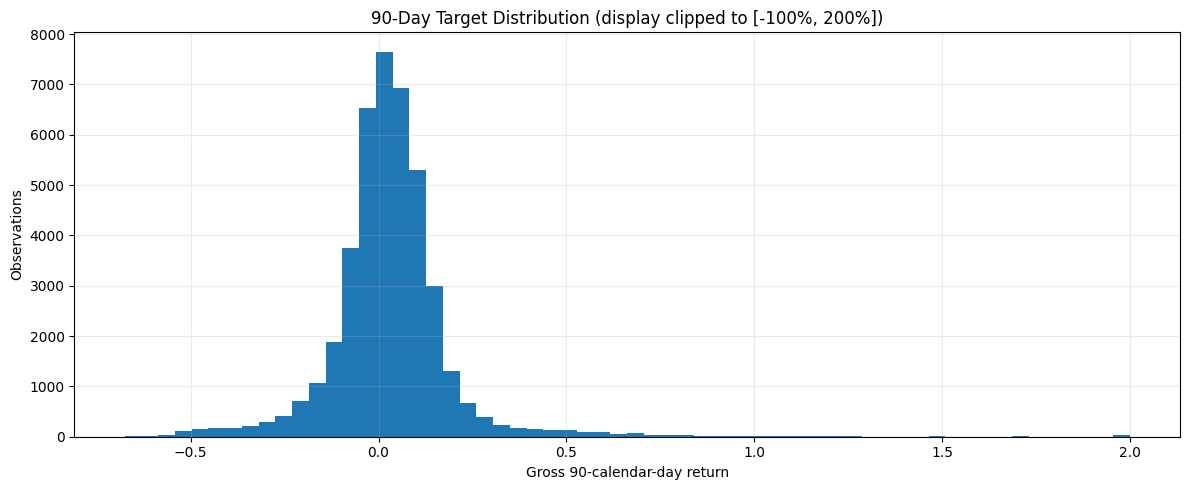

In [38]:
dev_panel_all = panel.loc[
    panel["date"].between(DEV_START, DEV_END)
].copy()

target_rows = dev_panel_all.loc[dev_panel_all["target"].notna()].copy()

print("Development rows:", len(dev_panel_all))
print("Completed targets:", len(target_rows))
print("Target coverage:", f"{len(target_rows) / max(len(dev_panel_all), 1):.2%}")

display(
    target_rows["target"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("90d_target")
)

fig, ax = plt.subplots()
ax.hist(target_rows["target"].clip(-1, 2), bins=60)
ax.set_title("90-Day Target Distribution (display clipped to [-100%, 200%])")
ax.set_xlabel("Gross 90-calendar-day return")
ax.set_ylabel("Observations")
plt.tight_layout()
plt.show()

In [39]:
target_extremes = (
    target_rows[
        ["date", "symbol", "sector", "entry_date", "label_end",
         "entry_price", "exit_price", "target"]
    ]
    .assign(abs_target=lambda x: x["target"].abs())
    .sort_values("abs_target", ascending=False)
)

display(target_extremes.head(30))

,date,symbol,sector,entry_date,label_end,entry_price,exit_price,target,abs_target
33344,2012-06-27,APDN,Healthcare,2012-06-28,2012-09-26,"1,800,000.00000","9,683,999.55000",4.38000,4.38000
33814,2012-07-20,APDN,Healthcare,2012-07-23,2012-10-22,"1,530,000.00000","8,117,999.70000",4.30588,4.30588
33257,2012-06-22,APDN,Healthcare,2012-06-25,2012-09-24,"1,800,000.00000","9,545,999.85000",4.30333,4.30333
33844,2012-07-23,APDN,Healthcare,2012-07-24,2012-10-22,"1,542,000.00000","8,117,999.70000",4.26459,4.26459
33755,2012-07-18,APDN,Healthcare,2012-07-19,2012-10-17,"1,260,000.00000","6,558,000.15000",4.20476,4.20476
33315,2012-06-26,APDN,Healthcare,2012-06-27,2012-09-25,"1,944,000.00000","9,720,000.30000",4.00000,4.00000
33402,2012-06-29,APDN,Healthcare,2012-07-02,2012-10-01,"1,764,000.00000","8,819,999.85000",4.00000,4.00000
33431,2012-07-02,APDN,Healthcare,2012-07-03,2012-10-01,"1,764,000.00000","8,819,999.85000",4.00000,4.00000
33373,2012-06-28,APDN,Healthcare,2012-06-29,2012-09-27,"1,800,000.00000","8,891,999.70000",3.94000,3.94000
33286,2012-06-25,APDN,Healthcare,2012-06-26,2012-09-24,"1,980,000.00000","9,545,999.85000",3.82121,3.82121


## 33. Restrict the research sample to historically eligible observations

The model sees only rows for which:
- the signal date is in 2010–2015;
- the stock is eligible under the 63-complete-return baseline rule;
- the stock is a member of the universe applicable to the next-session entry.

We intentionally **do not** require the future target to be observed here. Rows without a mature target can still receive validation predictions and can be selected by the strategy; their outcome is simply not scored until it is observable.

In [40]:
research_panel = panel.loc[
    panel["date"].between(DEV_START, DEV_END)
    & panel["eligible"].fillna(False).astype(bool)
    & panel["is_universe_member"].fillna(False).astype(bool)
].copy()

research_panel = research_panel.sort_values(
    ["date", "symbol"]
).reset_index(drop=True)

print("Eligible member rows:", len(research_panel))
print("Unique symbols:", research_panel["symbol"].nunique())
print("Date range:", research_panel["date"].min(), "to", research_panel["date"].max())

display(
    research_panel.groupby(research_panel["date"].dt.year)
    .agg(
        signal_rows=("symbol", "size"),
        distinct_dates=("date", "nunique"),
        distinct_symbols=("symbol", "nunique"),
        completed_targets=("target", "count")
    )
)

Eligible member rows: 43381


Unique symbols: 29
Date range: 2010-01-04 00:00:00 to 2015-12-30 00:00:00


,signal_rows,distinct_dates,distinct_symbols,completed_targets
date,,,,
2010,7245,252,29,7245
2011,7308,252,29,7308
2012,7250,250,29,7250
2013,7308,252,29,7308
2014,7243,252,29,7243
2015,7027,251,29,5353


## 34. Monthly signal schedule

The strategy creates one monthly cohort. The signal is the last market session of the month; features use information through that close, and the trade is entered at the next market session's close.

Quarterly membership is attached by the course helper based on the **quarter of that next-session entry**, so a quarter-end signal uses the newly available quarter's membership.

In [41]:
# The supplied market calendar (loaded in Part A) defines the signal schedule.
signal_calendar = (
    calendar[["date"]]
    .assign(date=lambda x: pd.to_datetime(x["date"]))
    .drop_duplicates()
    .sort_values("date")
)
signal_calendar = signal_calendar.loc[signal_calendar["date"].le(DEV_END)]

monthly_signal_dates = (
    signal_calendar.assign(month=signal_calendar["date"].dt.to_period("M"))
    .groupby("month")["date"]
    .max()
    .sort_values()
    .tolist()
)

monthly_signal_date_set = set(monthly_signal_dates)

print("Monthly signal dates:", len(monthly_signal_dates))
display(pd.DataFrame({"signal_date": monthly_signal_dates}).tail(15))

Monthly signal dates: 96


,signal_date
81,2014-10-31
82,2014-11-28
83,2014-12-31
84,2015-01-30
85,2015-02-27
86,2015-03-31
87,2015-04-30
88,2015-05-29
89,2015-06-30
90,2015-07-31


In [42]:
# Quarter-end signals: the entry falls in the next quarter, so membership
# must come from that new quarter's selection.
quarter_end_signals = research_panel.loc[
    research_panel["date"].isin(monthly_signal_date_set)
    & research_panel["date"].dt.month.isin([3, 6, 9, 12])
].assign(
    signal_quarter=lambda x: x["date"].dt.to_period("Q").astype(str),
    entry_quarter=lambda x: x["entry_date"].dt.to_period("Q").astype(str)
)

display(
    quarter_end_signals[
        ["date", "signal_quarter", "entry_date", "entry_quarter", "symbol",
         "universe_selection_date", "is_universe_member"]
    ].sort_values(["date", "symbol"]).tail(25)
)

,date,signal_quarter,entry_date,entry_quarter,symbol,universe_selection_date,is_universe_member
41655,2015-09-30,2015Q3,2015-10-01,2015Q4,APDN,2015-09-30,True
41656,2015-09-30,2015Q3,2015-10-01,2015Q4,BESS,2015-09-30,True
41657,2015-09-30,2015Q3,2015-10-01,2015Q4,BKNG,2015-09-30,True
41658,2015-09-30,2015Q3,2015-10-01,2015Q4,BRK-A,2015-09-30,True
41659,2015-09-30,2015Q3,2015-10-01,2015Q4,BRK-B,2015-09-30,True
41660,2015-09-30,2015Q3,2015-10-01,2015Q4,CVX,2015-09-30,True
41661,2015-09-30,2015Q3,2015-10-01,2015Q4,ETR,2015-09-30,True
41662,2015-09-30,2015Q3,2015-10-01,2015Q4,FCX,2015-09-30,True
41663,2015-09-30,2015Q3,2015-10-01,2015Q4,GE,2015-09-30,True
41664,2015-09-30,2015Q3,2015-10-01,2015Q4,IBM,2015-09-30,True


## 35. Chronological fold design

We use expanding-window validation:
- Fit before the first eligible signal in 2013; validate on 2013.
- Fit again before the first eligible signal in 2014; validate on 2014.
- Fit again before the first eligible signal in 2015; validate on 2015.

At each fold, the training observations must satisfy both:
1. their signal date is before the first validation signal;
2. their 90-day outcome (`label_end`) is strictly before the first validation signal.

This purges overlapping target windows from the training set. The model is held fixed for the full validation year; retraining is not used in this development experiment.

In [43]:
def make_chronological_fold(frame, validation_year, train_start=DEV_START):
    """Create an expanding-window fold with matured labels only.

    Validation includes all eligible member rows in that year, including rows
    whose future target has not matured by the classroom data cutoff.
    """
    valid = frame.loc[
        frame["date"].dt.year.eq(validation_year)
    ].copy()

    if valid.empty:
        raise ValueError(f"No eligible validation rows for {validation_year}")

    first_validation_signal = valid["date"].min()

    train = frame.loc[
        frame["date"].ge(train_start)
        & frame["date"].lt(first_validation_signal)
        & frame["label_end"].notna()
        & frame["label_end"].lt(first_validation_signal)
        & frame["target"].notna()
    ].copy()

    # Exclude non-finite labels explicitly.
    train = train.loc[np.isfinite(train["target"])].copy()

    if train.empty:
        raise ValueError(
            f"No matured training labels before {first_validation_signal.date()}"
        )

    assert train["date"].max() < first_validation_signal
    assert train["label_end"].max() < first_validation_signal
    assert valid["date"].min() == first_validation_signal

    return train, valid, first_validation_signal


fold_audits = []

for year in VALIDATION_YEARS:
    train_fold, valid_fold, first_signal = make_chronological_fold(
        research_panel, year
    )

    fold_audits.append({
        "validation_year": year,
        "first_validation_signal": first_signal,
        "training_rows": len(train_fold),
        "training_last_signal": train_fold["date"].max(),
        "latest_training_label_end": train_fold["label_end"].max(),
        "validation_rows_including_unmatured": len(valid_fold),
        "validation_rows_with_mature_targets": int(valid_fold["target"].notna().sum())
    })

fold_audit = pd.DataFrame(fold_audits)
display(fold_audit)

assert (
    pd.to_datetime(fold_audit["latest_training_label_end"])
    < pd.to_datetime(fold_audit["first_validation_signal"])
).all()

,validation_year,first_validation_signal,training_rows,training_last_signal,latest_training_label_end,validation_rows_including_unmatured,validation_rows_with_mature_targets
0,2013,2013-01-02,20034,2012-10-01,2012-12-31,7308,7308
1,2014,2014-01-02,27284,2013-10-01,2013-12-31,7243,7243
2,2015,2015-01-02,34590,2014-10-01,2014-12-31,7027,5353


## 36. Define candidate regression models

The models predict the continuous 90-day return. We compare:
- Ridge regression as a regularized linear baseline;
- Random Forest regression for nonlinearities and interactions;
- Histogram Gradient Boosting regression for boosted tree interactions.

The course's `make_pipeline` fits quantile clipping, median imputation and standardization of the features **inside each training fold**. The training target is also winsorized inside each fold at `TARGET_CLIP_QUANTILES`, using only that fold's training labels, so a few extreme 90-day moves (such as those found for BESS and APDN in Part A) do not dominate the fit.

We omit sector from the model features because the database's sector labels are current snapshot classifications, not dated historical sector records. Sector is used only by the portfolio grouping rule.

In [44]:
MODEL_FACTORIES = {
    "Ridge": lambda: Ridge(alpha=100.0),
    "RandomForest": lambda: RandomForestRegressor(
        n_estimators=250,
        max_depth=5,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": lambda: HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

def build_model_pipeline(model_name):
    if model_name not in MODEL_FACTORIES:
        raise KeyError(f"Unknown model: {model_name}")

    estimator = MODEL_FACTORIES[model_name]()

    return make_course_pipeline(
        model=estimator,
        numeric_features=FEATURE_COLUMNS,
        include_sector=False
    )

print("Models:", list(MODEL_FACTORIES))

Models: ['Ridge', 'RandomForest', 'HistGradientBoosting']


## 37. Validation metrics

We report:
- RMSE, MAE and $R^2$ for calibrated return predictions;
- mean daily Spearman rank IC, measuring cross-sectional ranking quality on every validation session;
- mean monthly-signal rank IC, the same measure restricted to the month-end signal dates on which the strategy actually trades.

Mean daily rank IC is the primary model-selection metric because the strategy ranks stocks. We also inspect the strategy's ex-post 90-day cohort returns, but do not compound overlapping cohort labels into a portfolio return.

In [45]:
def cross_sectional_rank_ic(frame, min_names=5):
    """Spearman correlation of prediction and target for each date."""
    ic_values = []
    for _, group in frame.groupby("date"):
        if (
            len(group) >= min_names
            and group["prediction"].nunique() > 1
            and group["target"].nunique() > 1
        ):
            ic_values.append(
                group["prediction"].corr(group["target"], method="spearman")
            )
    return pd.Series(ic_values, dtype=float).dropna()


def regression_and_rank_metrics(scored):
    """Metrics on rows with observed validation targets."""
    x = scored.loc[
        scored["target"].notna()
        & np.isfinite(scored["target"])
        & np.isfinite(scored["prediction"])
    ].copy()

    if x.empty:
        return {
            "n_scored_rows": 0,
            "RMSE": np.nan,
            "MAE": np.nan,
            "R2": np.nan,
            "mean_daily_rank_IC": np.nan,
            "rank_IC_dates": 0,
            "mean_monthly_signal_rank_IC": np.nan,
            "monthly_signal_IC_dates": 0
        }

    rmse = np.sqrt(mean_squared_error(x["target"], x["prediction"]))
    mae = mean_absolute_error(x["target"], x["prediction"])
    r2 = r2_score(x["target"], x["prediction"]) if len(x) >= 2 else np.nan

    daily_ic = cross_sectional_rank_ic(x)
    monthly_ic = cross_sectional_rank_ic(
        x.loc[x["date"].isin(monthly_signal_date_set)]
    )

    return {
        "n_scored_rows": len(x),
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "mean_daily_rank_IC": daily_ic.mean() if len(daily_ic) else np.nan,
        "rank_IC_dates": int(daily_ic.count()),
        "mean_monthly_signal_rank_IC": monthly_ic.mean() if len(monthly_ic) else np.nan,
        "monthly_signal_IC_dates": int(monthly_ic.count())
    }

## 38. Fit each model using matured training labels and predict validation rows

Predictions are made for all eligible member rows in each validation year, including rows whose target is not yet mature by December 31, 2015. Those rows remain eligible for selection; they are simply not included in ex-post scoring unless their outcome is observable.

In [46]:
prediction_frames = []
fold_metric_rows = []
fitted_models = {}

for model_name in MODEL_FACTORIES:
    print(f"\n===== MODEL: {model_name} =====")

    for year in VALIDATION_YEARS:
        train_fold, valid_fold, first_signal = make_chronological_fold(
            research_panel, year
        )

        estimator = build_model_pipeline(model_name)

        X_train = train_fold[FEATURE_COLUMNS]
        y_train_raw = train_fold["target"].astype(float)

        # Winsorize the training target using this fold's training labels only.
        clip_low, clip_high = y_train_raw.quantile(list(TARGET_CLIP_QUANTILES))
        y_train = y_train_raw.clip(clip_low, clip_high)

        X_valid = valid_fold[FEATURE_COLUMNS]

        estimator.fit(X_train, y_train)
        valid_prediction = estimator.predict(X_valid)

        fold_predictions = valid_fold[
            [
                "date", "symbol", "sector", "volatility_63",
                "eligible", "is_universe_member",
                "entry_date", "entry_price", "scheduled_exit",
                "label_end", "exit_price", "target"
            ]
        ].copy()

        fold_predictions["prediction"] = valid_prediction
        fold_predictions["model"] = model_name
        fold_predictions["fold_year"] = year
        fold_predictions["first_validation_signal"] = first_signal

        prediction_frames.append(fold_predictions)

        # Validation is scored on the raw (unclipped) target.
        metrics = regression_and_rank_metrics(fold_predictions)
        metrics.update({
            "model": model_name,
            "validation_year": year,
            "first_validation_signal": first_signal,
            "training_rows": len(train_fold),
            "validation_candidate_rows": len(valid_fold),
            "train_target_clip_low": clip_low,
            "train_target_clip_high": clip_high,
            "train_targets_clipped": int(
                (y_train_raw.lt(clip_low) | y_train_raw.gt(clip_high)).sum()
            )
        })
        fold_metric_rows.append(metrics)

        fitted_models[(model_name, year)] = estimator

        print(
            f"{year}: train={len(train_fold):,}, "
            f"validation={len(valid_fold):,}, "
            f"daily Rank IC={metrics['mean_daily_rank_IC']:.4f}, "
            f"monthly-signal Rank IC={metrics['mean_monthly_signal_rank_IC']:.4f}"
        )

validation_predictions = pd.concat(
    prediction_frames, ignore_index=True
).sort_values(
    ["model", "date", "symbol"]
).reset_index(drop=True)

fold_metrics = pd.DataFrame(fold_metric_rows)

display(fold_metrics)


===== MODEL: Ridge =====


2013: train=20,034, validation=7,308, daily Rank IC=-0.0471, monthly-signal Rank IC=-0.0341
2014: train=27,284, validation=7,243, daily Rank IC=0.0248, monthly-signal Rank IC=0.0243


2015: train=34,590, validation=7,027, daily Rank IC=0.1622, monthly-signal Rank IC=0.1919

===== MODEL: RandomForest =====


2013: train=20,034, validation=7,308, daily Rank IC=0.0529, monthly-signal Rank IC=0.0604


2014: train=27,284, validation=7,243, daily Rank IC=0.0269, monthly-signal Rank IC=0.0182


2015: train=34,590, validation=7,027, daily Rank IC=0.1039, monthly-signal Rank IC=0.1374

===== MODEL: HistGradientBoosting =====


2013: train=20,034, validation=7,308, daily Rank IC=0.0449, monthly-signal Rank IC=0.0558


2014: train=27,284, validation=7,243, daily Rank IC=0.0185, monthly-signal Rank IC=-0.0110


2015: train=34,590, validation=7,027, daily Rank IC=0.0588, monthly-signal Rank IC=0.0978


,n_scored_rows,RMSE,MAE,R2,mean_daily_rank_IC,rank_IC_dates,mean_monthly_signal_rank_IC,monthly_signal_IC_dates,model,validation_year,first_validation_signal,training_rows,validation_candidate_rows,train_target_clip_low,train_target_clip_high,train_targets_clipped
0,7308,0.14176,0.09239,0.03078,-0.04712,252,-0.03407,12,Ridge,2013,2013-01-02,20034,7308,-0.41879,0.69059,402
1,7243,0.14450,0.09139,-0.06838,0.02483,252,0.02428,12,Ridge,2014,2014-01-02,27284,7243,-0.42003,0.66208,546
2,5353,0.18954,0.11186,-0.05147,0.16216,189,0.19194,9,Ridge,2015,2015-01-02,34590,7027,-0.41667,0.62997,690
3,7308,0.14252,0.09289,0.02038,0.05291,252,0.06037,12,RandomForest,2013,2013-01-02,20034,7308,-0.41879,0.69059,402
4,7243,0.16071,0.09440,-0.32161,0.02691,252,0.01823,12,RandomForest,2014,2014-01-02,27284,7243,-0.42003,0.66208,546
5,5353,0.18471,0.10799,0.00139,0.10395,189,0.13744,9,RandomForest,2015,2015-01-02,34590,7027,-0.41667,0.62997,690
6,7308,0.14341,0.09818,0.00810,0.04490,252,0.05575,12,HistGradientBoosting,2013,2013-01-02,20034,7308,-0.41879,0.69059,402
7,7243,0.16426,0.09727,-0.38059,0.01845,252,-0.01100,12,HistGradientBoosting,2014,2014-01-02,27284,7243,-0.42003,0.66208,546
8,5353,0.18928,0.11470,-0.04856,0.05881,189,0.09781,9,HistGradientBoosting,2015,2015-01-02,34590,7027,-0.41667,0.62997,690


## 39. Compare model validation results

We average fold-level metrics so that no single validation year determines the result. Models are ranked by the highest mean daily rank IC across validation years, with mean MAE as the tie-break.

In [47]:
model_summary = (
    fold_metrics.groupby("model")
    .agg(
        mean_Rank_IC=("mean_daily_rank_IC", "mean"),
        std_Rank_IC=("mean_daily_rank_IC", "std"),
        mean_monthly_signal_IC=("mean_monthly_signal_rank_IC", "mean"),
        mean_RMSE=("RMSE", "mean"),
        mean_MAE=("MAE", "mean"),
        mean_R2=("R2", "mean"),
        total_scored_rows=("n_scored_rows", "sum"),
        validation_folds=("validation_year", "nunique")
    )
    .reset_index()
    .sort_values(
        ["mean_Rank_IC", "mean_MAE"],
        ascending=[False, True]
    )
)

display(model_summary)

,model,mean_Rank_IC,std_Rank_IC,mean_monthly_signal_IC,mean_RMSE,mean_MAE,mean_R2,total_scored_rows,validation_folds
1,RandomForest,0.06125,0.03919,0.07201,0.16265,0.09843,-0.09994,19904,3
2,Ridge,0.04662,0.10633,0.06072,0.15860,0.09854,-0.02969,19904,3
0,HistGradientBoosting,0.04072,0.02050,0.04752,0.16565,0.10339,-0.14035,19904,3


## 40. Define the 50/50 sector-aware selection rule

This selector uses only the current signal-date predictions and trailing volatility. It does not inspect `target`, `label_end`, exit prices or any future outcome.

**Growth sleeve**
- One highest-predicted-return name per sector among positive predictions. Trailing volatility is not required for this sleeve.

**Defensive sleeve**
- Within each sector, find the 40th percentile of trailing 63-session volatility among names with an observed volatility.
- Keep names at or below that sector-specific cutoff.
- Remove any name already chosen for the growth sleeve.
- Select the highest predicted positive-return name among the remaining low-volatility names.

**Weights**
- Split the 50% sleeve allocation equally among its selected names.
- Cap each name at 10% of total portfolio capital.
- Since at most one name per sector is chosen in each sleeve and duplicates are disallowed, sector exposure is at most 20%.
- Any amount not allocated due to missing eligible picks or caps remains cash.

In [48]:
def select_sector_sleeves(
    cross_section,
    prediction_col="prediction",
    sector_col="sector",
    volatility_col="volatility_63",
    growth_share=GROWTH_SLEEVE_SHARE,
    defensive_share=DEFENSIVE_SLEEVE_SHARE,
    defensive_quantile=DEFENSIVE_VOLATILITY_QUANTILE,
    max_position_weight=MAX_POSITION_WEIGHT,
    max_sector_weight=MAX_SECTOR_WEIGHT
):
    """Create the proposed sector-aware growth/defensive portfolio.

    This function uses prediction, sector and trailing volatility only.
    It deliberately does not use realized target or future label fields.
    """
    required = {
        "symbol", prediction_col, sector_col, volatility_col
    }
    missing = required.difference(cross_section.columns)
    if missing:
        raise KeyError(f"Missing selection columns: {sorted(missing)}")

    data = cross_section.copy()

    data[prediction_col] = pd.to_numeric(
        data[prediction_col], errors="coerce"
    )
    data[volatility_col] = pd.to_numeric(
        data[volatility_col], errors="coerce"
    )

    # A usable prediction and sector are required for both sleeves.
    data = data.loc[
        data[prediction_col].notna()
        & np.isfinite(data[prediction_col])
        & data[sector_col].notna()
    ].copy()

    data[sector_col] = data[sector_col].astype(str)
    data = data.loc[
        ~data[sector_col].str.strip().str.lower().isin(
            ["", "unknown", "nan", "none"]
        )
    ]

    # One row per stock on a signal date.
    if data["symbol"].duplicated().any():
        raise ValueError("Expected at most one row per symbol per signal date.")

    growth_picks = []

    for sector, group in data.groupby(sector_col, sort=True):
        candidates = group.loc[group[prediction_col] > 0].copy()
        if candidates.empty:
            continue

        winner = candidates.sort_values(
            [prediction_col, "symbol"],
            ascending=[False, True],
            kind="mergesort"
        ).head(1).copy()

        winner["sleeve"] = "growth"
        growth_picks.append(winner)

    growth = (
        pd.concat(growth_picks, ignore_index=True)
        if growth_picks else data.head(0).copy()
    )

    growth_symbols = set(growth["symbol"])

    defensive_picks = []

    # The defensive sleeve additionally needs an observed trailing volatility.
    volatility_data = data.loc[
        data[volatility_col].notna() & np.isfinite(data[volatility_col])
    ]

    for sector, group in volatility_data.groupby(sector_col, sort=True):
        # The volatility threshold is calculated within the sector.
        volatility_cutoff = group[volatility_col].quantile(defensive_quantile)

        candidates = group.loc[
            (group[volatility_col] <= volatility_cutoff)
            & (group[prediction_col] > 0)
            & (~group["symbol"].isin(growth_symbols))
        ].copy()

        if candidates.empty:
            continue

        winner = candidates.sort_values(
            [prediction_col, "symbol"],
            ascending=[False, True],
            kind="mergesort"
        ).head(1).copy()

        winner["sleeve"] = "defensive"
        winner["sector_volatility_cutoff"] = volatility_cutoff
        defensive_picks.append(winner)

    defensive = (
        pd.concat(defensive_picks, ignore_index=True)
        if defensive_picks else data.head(0).copy()
    )

    selected = pd.concat(
        [growth, defensive],
        ignore_index=True,
        sort=False
    )

    if selected.empty:
        selected["weight"] = pd.Series(dtype=float)
        return selected

    # Equal weights within each sleeve, subject to the per-name cap.
    selected["weight"] = 0.0

    for sleeve, sleeve_share in [
        ("growth", growth_share),
        ("defensive", defensive_share)
    ]:
        mask = selected["sleeve"].eq(sleeve)
        n_names = int(mask.sum())

        if n_names:
            equal_weight = sleeve_share / n_names
            selected.loc[mask, "weight"] = min(
                equal_weight, max_position_weight
            )

    # No duplicate stock across sleeves.
    assert not selected["symbol"].duplicated().any()

    # Name and sector concentration constraints.
    assert (selected["weight"] <= max_position_weight + 1e-12).all()

    sector_exposure = selected.groupby(sector_col)["weight"].sum()
    assert (sector_exposure <= max_sector_weight + 1e-12).all()

    assert selected["weight"].sum() <= 1.0 + 1e-12

    # Return only fields available to the selection rule.
    # Future target and exit fields are attached only later,
    # in a separate ex-post audit merge.
    output_columns = [
        "symbol", sector_col, prediction_col, volatility_col,
        "sleeve", "weight"
    ]
    if "sector_volatility_cutoff" in selected.columns:
        output_columns.append("sector_volatility_cutoff")

    return selected[output_columns].sort_values(
        ["sleeve", sector_col, prediction_col],
        ascending=[True, True, False]
    ).reset_index(drop=True)

## 41. Smoke-test the sector selector

This uses a small synthetic cross-section only to verify the portfolio logic. It is not research data and is not used for model validation.

In [49]:
toy = pd.DataFrame({
    "symbol": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "sector": ["Tech", "Tech", "Tech", "Finance", "Finance", "Finance", "Health", "Health"],
    "prediction": [0.15, 0.09, 0.07, 0.11, 0.08, 0.04, 0.06, -0.02],
    "volatility_63": [0.50, 0.15, 0.20, 0.40, 0.10, 0.18, 0.25, 0.12]
})

toy_picks = select_sector_sleeves(toy)
display(toy_picks[["symbol", "sector", "sleeve", "prediction", "volatility_63", "weight"]])

assert not toy_picks["symbol"].duplicated().any()
assert (toy_picks["weight"] <= MAX_POSITION_WEIGHT + 1e-12).all()
assert toy_picks.groupby("sector")["weight"].sum().max() <= MAX_SECTOR_WEIGHT + 1e-12
assert toy_picks["weight"].sum() <= 1.0 + 1e-12
assert "target" not in toy_picks.columns
assert "label_end" not in toy_picks.columns

# A name with missing volatility can still be a growth pick, never a defensive pick.
toy_missing_vol = toy.assign(
    volatility_63=lambda x: x["volatility_63"].where(x["symbol"].ne("A"))
)
toy_missing_vol_picks = select_sector_sleeves(toy_missing_vol)
assert toy_missing_vol_picks.loc[
    toy_missing_vol_picks["symbol"].eq("A"), "sleeve"
].tolist() == ["growth"]

print("Sector sleeve selector checks passed.")

,symbol,sector,sleeve,prediction,volatility_63,weight
0,E,Finance,defensive,0.08000,0.10000,0.10000
1,B,Tech,defensive,0.09000,0.15000,0.10000
2,D,Finance,growth,0.11000,0.40000,0.10000
3,G,Health,growth,0.06000,0.25000,0.10000
4,A,Tech,growth,0.15000,0.50000,0.10000


Sector sleeve selector checks passed.


## 42. Apply the selector to monthly validation predictions

We first filter to the final market session of each month. The selector sees all eligible member candidates on that signal date, including candidates whose future labels are not yet mature.

The strategy does **not** use future target availability, exit prices or realized returns to decide which stocks to select.

In [50]:
def build_monthly_cohort_selections(prediction_frame):
    """Apply fixed sleeve strategy to monthly signal dates.

    Returns planned picks with label audit fields attached for ex-post
    evaluation only. Selection itself does not use those label fields.
    """
    monthly_rows = prediction_frame.loc[
        prediction_frame["date"].isin(monthly_signal_date_set)
    ].copy()

    selections = []

    for signal_date, cross_section in monthly_rows.groupby("date", sort=True):
        picks = select_sector_sleeves(cross_section)

        if picks.empty:
            continue

        picks = picks.copy()
        picks["signal_date"] = signal_date

        # Label/audit columns are attached only after selection.
        audit_columns = [
            "symbol", "target", "entry_date", "entry_price",
            "scheduled_exit", "label_end", "exit_price"
        ]

        audit = cross_section[audit_columns].drop_duplicates("symbol")

        picks = picks.merge(
            audit,
            on="symbol",
            how="left",
            validate="one_to_one"
        )

        selections.append(picks)

    if not selections:
        return pd.DataFrame()

    return pd.concat(selections, ignore_index=True)

## 43. Ex-post cohort evaluation

For each monthly signal date:
- A selected name's contribution is its portfolio weight multiplied by its realized 90-day target.
- Unallocated capital remains in cash and earns 0% in this diagnostic.
- If any selected name has a missing target, the **entire cohort is marked incomplete**. We do not drop only that stock, because doing so would bias the cohort result.
- If candidates exist but none has a positive prediction, the cohort stays fully in cash and has a 0% gross cohort return.
- If the signal date has no eligible candidate rows at all (for example, a final month whose next-session entry lies beyond the classroom data), the cohort is marked as not observed rather than counted as a 0% cash cohort.

Monthly cohorts overlap. The results below are descriptive 90-day cohort statistics, not a daily compounded portfolio backtest.

In [51]:
def evaluate_monthly_cohorts(selections, prediction_frame):
    rows = []

    candidate_counts = prediction_frame.groupby("date")["symbol"].nunique()

    # Include every calendar month-end in the validation period.
    years = sorted(prediction_frame["fold_year"].dropna().unique())

    for year in years:
        year_signal_dates = [
            d for d in monthly_signal_dates if d.year == int(year)
        ]

        for signal_date in year_signal_dates:
            n_candidates = int(candidate_counts.get(signal_date, 0))

            picks = (
                selections.loc[selections["signal_date"].eq(signal_date)].copy()
                if not selections.empty
                else pd.DataFrame()
            )

            if picks.empty:
                has_candidates = n_candidates > 0
                rows.append({
                    "fold_year": int(year),
                    "signal_date": signal_date,
                    "n_candidates": n_candidates,
                    "status": (
                        "all cash (no positive prediction)"
                        if has_candidates else "no candidate rows"
                    ),
                    "n_positions": 0,
                    "growth_positions": 0,
                    "defensive_positions": 0,
                    "invested_weight": 0.0,
                    "cash_weight": 1.0,
                    "fully_observed": has_candidates,
                    "cohort_return": 0.0 if has_candidates else np.nan,
                    "growth_sleeve_return": 0.0 if has_candidates else np.nan,
                    "defensive_sleeve_return": 0.0 if has_candidates else np.nan
                })
                continue

            fully_observed = (
                picks["target"].notna().all()
                and picks["entry_price"].notna().all()
                and picks["exit_price"].notna().all()
            )

            invested_weight = float(picks["weight"].sum())
            cash_weight = max(0.0, 1.0 - invested_weight)

            if fully_observed:
                contribution = picks["weight"] * picks["target"]
                cohort_return = float(contribution.sum())

                growth_contribution = float(
                    contribution.loc[picks["sleeve"].eq("growth")].sum()
                )
                defensive_contribution = float(
                    contribution.loc[picks["sleeve"].eq("defensive")].sum()
                )

                growth_return = growth_contribution / GROWTH_SLEEVE_SHARE
                defensive_return = defensive_contribution / DEFENSIVE_SLEEVE_SHARE
            else:
                cohort_return = np.nan
                growth_return = np.nan
                defensive_return = np.nan

            rows.append({
                "fold_year": int(year),
                "signal_date": signal_date,
                "n_candidates": n_candidates,
                "status": "observed" if fully_observed else "incomplete",
                "n_positions": len(picks),
                "growth_positions": int(picks["sleeve"].eq("growth").sum()),
                "defensive_positions": int(picks["sleeve"].eq("defensive").sum()),
                "invested_weight": invested_weight,
                "cash_weight": cash_weight,
                "fully_observed": bool(fully_observed),
                "cohort_return": cohort_return,
                "growth_sleeve_return": growth_return,
                "defensive_sleeve_return": defensive_return
            })

    return pd.DataFrame(rows)

## 44. Run strategy selection and cohort evaluation for each model

We apply the same fixed 50/50 portfolio rule to every model's validation predictions.

In [52]:
strategy_selection_frames = []
cohort_result_frames = []

for model_name in MODEL_FACTORIES:
    model_predictions = validation_predictions.loc[
        validation_predictions["model"].eq(model_name)
    ].copy()

    selections = build_monthly_cohort_selections(model_predictions)

    if not selections.empty:
        selections["model"] = model_name
        strategy_selection_frames.append(selections)

    model_cohorts = evaluate_monthly_cohorts(
        selections,
        model_predictions
    )
    model_cohorts["model"] = model_name
    cohort_result_frames.append(model_cohorts)

strategy_selections = (
    pd.concat(strategy_selection_frames, ignore_index=True)
    if strategy_selection_frames else pd.DataFrame()
)

cohort_results = pd.concat(
    cohort_result_frames, ignore_index=True
)

print("Selected stock rows:", len(strategy_selections))
print("Monthly cohort rows:", len(cohort_results))

display(
    cohort_results.groupby(["model", "status"])
    .size()
    .unstack(fill_value=0)
)
display(strategy_selections.head(20))
display(cohort_results.head(15))

Selected stock rows: 1792
Monthly cohort rows: 108


status,incomplete,no candidate rows,observed
model,,,
HistGradientBoosting,2,1,33
RandomForest,2,1,33
Ridge,2,1,33


,symbol,sector,prediction,volatility_63,sleeve,weight,sector_volatility_cutoff,signal_date,target,entry_date,entry_price,scheduled_exit,label_end,exit_price,model
0,SCCO,Basic Materials,0.02000,0.21795,defensive,0.07143,0.30014,2013-01-31,-0.17117,2013-02-01,26.99000,2013-05-02,2013-05-02,22.37000,Ridge
1,PG,Consumer Defensive,0.02805,0.14197,defensive,0.07143,0.14501,2013-01-31,0.03166,2013-02-01,54.33000,2013-05-02,2013-05-02,56.05000,Ridge
2,BRK-A,Financial Services,0.02158,0.13311,defensive,0.07143,0.13618,2013-01-31,0.09363,2013-02-01,"147,086.00000",2013-05-02,2013-05-02,"160,857.00000",Ridge
3,JNJ,Healthcare,0.03983,0.08397,defensive,0.07143,0.38640,2013-01-31,0.15733,2013-02-01,53.58000,2013-05-02,2013-05-02,62.01000,Ridge
4,MMM,Industrials,0.02086,0.13028,defensive,0.07143,0.15481,2013-01-31,0.05052,2013-02-01,58.19000,2013-05-02,2013-05-02,61.13000,Ridge
5,SPG,Real Estate,0.02656,0.12072,defensive,0.07143,0.13451,2013-01-31,0.10699,2013-02-01,88.70000,2013-05-02,2013-05-02,98.19000,Ridge
6,ETR,Utilities,0.06067,0.16776,defensive,0.07143,0.59992,2013-01-31,0.11827,2013-02-01,39.40000,2013-05-02,2013-05-02,44.06000,Ridge
7,FCX,Basic Materials,0.07426,0.42341,growth,0.04545,NaN,2013-01-31,-0.14296,2013-02-01,28.89000,2013-05-02,2013-05-02,24.76000,Ridge
8,T,Communication Services,0.02724,0.16780,growth,0.04545,NaN,2013-01-31,0.07074,2013-02-01,13.43000,2013-05-02,2013-05-02,14.38000,Ridge
9,MCD,Consumer Cyclical,0.03707,0.11476,growth,0.04545,NaN,2013-01-31,0.07221,2013-02-01,70.07000,2013-05-02,2013-05-02,75.13000,Ridge


,fold_year,signal_date,n_candidates,status,n_positions,growth_positions,defensive_positions,invested_weight,cash_weight,fully_observed,cohort_return,growth_sleeve_return,defensive_sleeve_return,model
0,2013,2013-01-31,29,observed,18,11,7,1.00000,0.00000,True,0.04484,0.03437,0.05532,Ridge
1,2013,2013-02-28,29,observed,20,11,9,1.00000,0.00000,True,0.01950,0.00179,0.03722,Ridge
2,2013,2013-03-28,29,observed,17,11,6,1.00000,0.00000,True,0.01800,0.02866,0.00735,Ridge
3,2013,2013-04-30,29,observed,20,11,9,1.00000,0.00000,True,0.03546,0.07281,-0.00188,Ridge
4,2013,2013-05-31,29,observed,19,11,8,1.00000,0.00000,True,-0.04081,-0.02509,-0.05653,Ridge
5,2013,2013-06-28,29,observed,17,11,6,1.00000,0.00000,True,0.01301,0.03649,-0.01047,Ridge
6,2013,2013-07-31,29,observed,18,11,7,1.00000,0.00000,True,0.08939,0.13651,0.04227,Ridge
7,2013,2013-08-30,29,observed,19,11,8,1.00000,0.00000,True,0.12807,0.19728,0.05886,Ridge
8,2013,2013-09-30,29,observed,19,10,9,1.00000,0.00000,True,0.10284,0.13761,0.06808,Ridge
9,2013,2013-10-31,29,observed,19,11,8,1.00000,0.00000,True,-0.01073,0.00276,-0.02421,Ridge


## 45. Compare validation cohort diagnostics

We report average and median gross 90-day cohort returns only for fully observed cohorts. We also report how many cohorts were fully observable. Low coverage is a warning: the classroom data cutoff may not allow every selected position to mature, and such cohorts are not silently omitted stock by stock.

Do not interpret these overlapping cohort means as CAGR, Sharpe or final portfolio returns.

In [53]:
cohort_summary = (
    cohort_results.groupby(["model", "fold_year"])
    .agg(
        total_monthly_cohorts=("signal_date", "count"),
        fully_observed_cohorts=("fully_observed", "sum"),
        mean_cohort_return=("cohort_return", "mean"),
        median_cohort_return=("cohort_return", "median"),
        positive_cohort_pct=(
            "cohort_return",
            lambda x: (x.dropna() > 0).mean() * 100 if x.notna().any() else np.nan
        ),
        mean_positions=("n_positions", "mean"),
        mean_cash_weight=("cash_weight", "mean"),
        mean_growth_return=("growth_sleeve_return", "mean"),
        mean_defensive_return=("defensive_sleeve_return", "mean")
    )
    .reset_index()
)

cohort_summary["cohort_completion_pct"] = (
    cohort_summary["fully_observed_cohorts"]
    / cohort_summary["total_monthly_cohorts"] * 100
)

display(cohort_summary)

,model,fold_year,total_monthly_cohorts,fully_observed_cohorts,mean_cohort_return,median_cohort_return,positive_cohort_pct,mean_positions,mean_cash_weight,mean_growth_return,mean_defensive_return,cohort_completion_pct
0,HistGradientBoosting,2013,12,12,0.03511,0.02040,75.00000,15.41667,0.02500,0.05477,0.01546,100.00000
1,HistGradientBoosting,2014,12,12,0.02057,0.01720,75.00000,16.16667,0.04167,0.01718,0.02395,100.00000
2,HistGradientBoosting,2015,12,9,0.01474,0.02153,77.77778,15.58333,0.10000,0.02403,0.00544,75.00000
3,RandomForest,2013,12,12,0.03287,0.02384,66.66667,18.00000,0.00833,0.04463,0.02111,100.00000
4,RandomForest,2014,12,12,0.01270,0.00969,50.00000,15.75000,0.06667,0.00891,0.01650,100.00000
5,RandomForest,2015,12,9,0.02387,0.03634,66.66667,15.66667,0.10833,0.03913,0.00860,75.00000
6,Ridge,2013,12,12,0.03246,0.01875,75.00000,18.33333,0.00000,0.04819,0.01672,100.00000
7,Ridge,2014,12,12,0.02249,0.02589,66.66667,17.91667,0.00000,0.01995,0.02503,100.00000
8,Ridge,2015,12,9,0.01561,0.02728,66.66667,16.50000,0.09167,0.03591,-0.00468,75.00000


## 46. Combine model-ranking and strategy diagnostics

The primary model-selection metric is mean fold rank IC. Average cohort return is a secondary strategy diagnostic. No final-test data is used in this comparison.

In [54]:
strategy_overall = (
    cohort_summary.groupby("model")
    .agg(
        mean_validation_cohort_return=("mean_cohort_return", "mean"),
        mean_validation_completion_pct=("cohort_completion_pct", "mean"),
        mean_validation_cash_weight=("mean_cash_weight", "mean"),
        total_validation_cohorts=("total_monthly_cohorts", "sum"),
        fully_observed_cohorts=("fully_observed_cohorts", "sum")
    )
    .reset_index()
)

model_selection_table = model_summary.merge(
    strategy_overall,
    on="model",
    how="left",
    validate="one_to_one"
).sort_values(
    ["mean_Rank_IC", "mean_MAE"],
    ascending=[False, True]
)

display(model_selection_table)

,model,mean_Rank_IC,std_Rank_IC,mean_monthly_signal_IC,mean_RMSE,mean_MAE,mean_R2,total_scored_rows,validation_folds,mean_validation_cohort_return,mean_validation_completion_pct,mean_validation_cash_weight,total_validation_cohorts,fully_observed_cohorts
0,RandomForest,0.06125,0.03919,0.07201,0.16265,0.09843,-0.09994,19904,3,0.02315,91.66667,0.06111,36,33
1,Ridge,0.04662,0.10633,0.06072,0.15860,0.09854,-0.02969,19904,3,0.02352,91.66667,0.03056,36,33
2,HistGradientBoosting,0.04072,0.02050,0.04752,0.16565,0.10339,-0.14035,19904,3,0.02347,91.66667,0.05556,36,33


## 47. Select the development model

We select the model with the highest average daily Spearman rank IC across the 2013–2015 folds, using mean MAE as the tie-break. This is a development-only choice; the year-by-year results below show how stable it is.

In [55]:
ranked_models = model_selection_table.dropna(
    subset=["mean_Rank_IC"]
).sort_values(
    ["mean_Rank_IC", "mean_MAE"],
    ascending=[False, True]
)

if ranked_models.empty:
    raise RuntimeError(
        "No model has enough cross-sectional validation data to calculate Rank IC."
    )

SELECTED_MODEL_NAME = ranked_models.iloc[0]["model"]

print("Selected development model:", SELECTED_MODEL_NAME)
print("Selection rule: highest mean validation daily Rank IC; mean MAE as tie-break.")
display(ranked_models)

Selected development model: RandomForest
Selection rule: highest mean validation daily Rank IC; mean MAE as tie-break.


,model,mean_Rank_IC,std_Rank_IC,mean_monthly_signal_IC,mean_RMSE,mean_MAE,mean_R2,total_scored_rows,validation_folds,mean_validation_cohort_return,mean_validation_completion_pct,mean_validation_cash_weight,total_validation_cohorts,fully_observed_cohorts
0,RandomForest,0.06125,0.03919,0.07201,0.16265,0.09843,-0.09994,19904,3,0.02315,91.66667,0.06111,36,33
1,Ridge,0.04662,0.10633,0.06072,0.15860,0.09854,-0.02969,19904,3,0.02352,91.66667,0.03056,36,33
2,HistGradientBoosting,0.04072,0.02050,0.04752,0.16565,0.10339,-0.14035,19904,3,0.02347,91.66667,0.05556,36,33


## 48. Inspect selected-model validation predictions

These predictions are out-of-fold: each year was predicted by a model fit only on observations with targets already matured before that year's first signal.

In [56]:
selected_model_predictions = validation_predictions.loc[
    validation_predictions["model"].eq(SELECTED_MODEL_NAME)
].copy()

selected_model_monthly = selected_model_predictions.loc[
    selected_model_predictions["date"].isin(monthly_signal_date_set)
].copy()

display(
    selected_model_monthly[
        [
            "date", "symbol", "sector", "prediction",
            "volatility_63", "target", "entry_date", "label_end"
        ]
    ].sort_values(["date", "sector", "prediction"], ascending=[True, True, False])
    .head(40)
)

,date,symbol,sector,prediction,volatility_63,target,entry_date,label_end
22167,2013-01-31,FCX,Basic Materials,0.03526,0.42341,-0.14296,2013-02-01,2013-05-02
22180,2013-01-31,SCCO,Basic Materials,0.03476,0.21795,-0.17117,2013-02-01,2013-05-02
22183,2013-01-31,TSYS,Communication Services,0.03389,0.34755,-0.11570,2013-02-01,2013-05-02
22182,2013-01-31,T,Communication Services,0.03200,0.16780,0.07074,2013-02-01,2013-05-02
22162,2013-01-31,BKNG,Consumer Cyclical,0.06715,0.29360,0.03266,2013-02-01,2013-05-02
22176,2013-01-31,ORLY,Consumer Cyclical,0.03185,0.18149,0.15783,2013-02-01,2013-05-02
22173,2013-01-31,MCD,Consumer Cyclical,0.03170,0.11476,0.07221,2013-02-01,2013-05-02
22172,2013-01-31,KO,Consumer Defensive,0.03180,0.14577,0.12568,2013-02-01,2013-05-02
22178,2013-01-31,PG,Consumer Defensive,0.03170,0.14197,0.03166,2013-02-01,2013-05-02
22185,2013-01-31,WMT,Consumer Defensive,0.02837,0.15932,0.11983,2013-02-01,2013-05-02


## 49. Visualize validation Rank IC by year

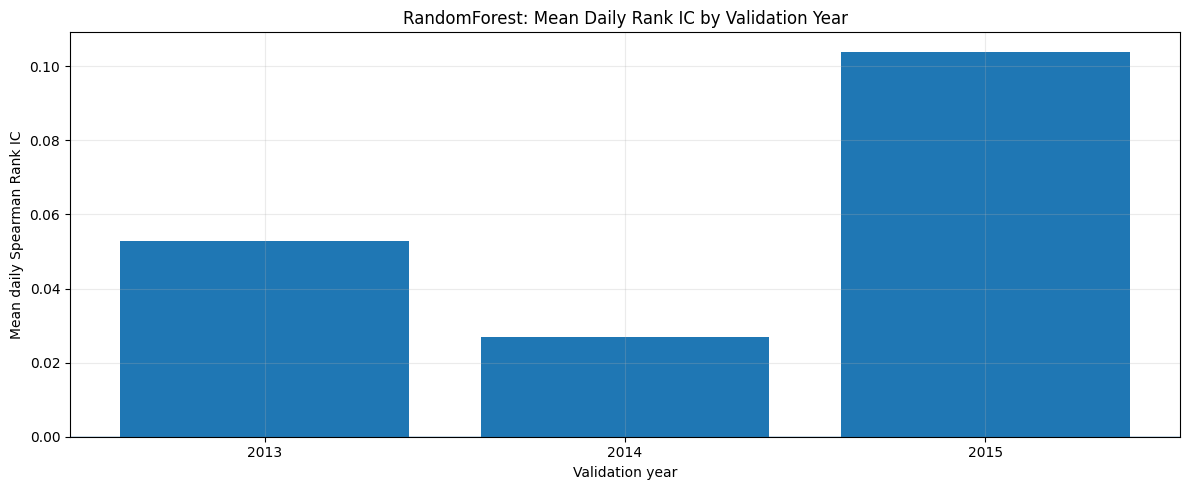

In [57]:
selected_fold_metrics = fold_metrics.loc[
    fold_metrics["model"].eq(SELECTED_MODEL_NAME)
].sort_values("validation_year")

fig, ax = plt.subplots()
ax.bar(
    selected_fold_metrics["validation_year"].astype(str),
    selected_fold_metrics["mean_daily_rank_IC"]
)
ax.axhline(0, linewidth=1)
ax.set_title(f"{SELECTED_MODEL_NAME}: Mean Daily Rank IC by Validation Year")
ax.set_xlabel("Validation year")
ax.set_ylabel("Mean daily Spearman Rank IC")
plt.tight_layout()
plt.show()

## 50. Visualize validation monthly cohort returns

Only fully observed cohorts have a numeric return. Missing cohorts remain gaps in the plot; do not interpolate them.

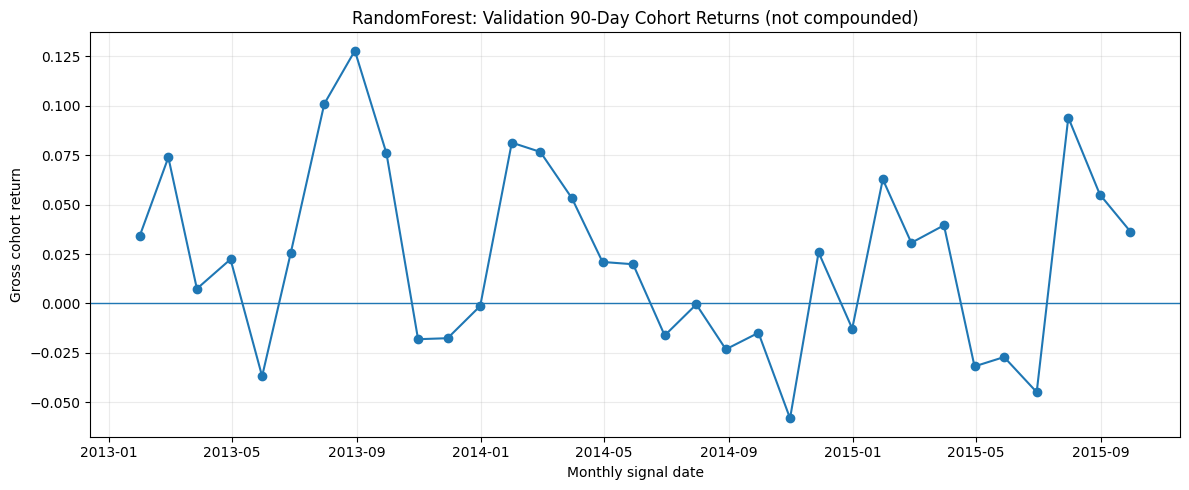

,fold_year,signal_date,n_candidates,status,n_positions,growth_positions,defensive_positions,invested_weight,cash_weight,fully_observed,cohort_return,growth_sleeve_return,defensive_sleeve_return,model
36,2013,2013-01-31,29,observed,21,11,10,1.00000,0.00000,True,0.03428,0.02248,0.04608,RandomForest
37,2013,2013-02-28,29,observed,18,11,7,1.00000,0.00000,True,0.07393,0.07347,0.07439,RandomForest
38,2013,2013-03-28,29,observed,19,11,8,1.00000,0.00000,True,0.00744,-0.04082,0.05570,RandomForest
39,2013,2013-04-30,29,observed,19,11,8,1.00000,0.00000,True,0.02236,0.04264,0.00209,RandomForest
40,2013,2013-05-31,29,observed,19,11,8,1.00000,0.00000,True,-0.03685,-0.02818,-0.04551,RandomForest
41,2013,2013-06-28,29,observed,17,11,6,1.00000,0.00000,True,0.02532,0.06664,-0.01599,RandomForest
42,2013,2013-07-31,29,observed,19,11,8,1.00000,0.00000,True,0.10100,0.17624,0.02575,RandomForest
43,2013,2013-08-30,29,observed,19,11,8,1.00000,0.00000,True,0.12790,0.18610,0.06970,RandomForest
44,2013,2013-09-30,29,observed,16,11,5,1.00000,0.00000,True,0.07596,0.06310,0.08882,RandomForest
45,2013,2013-10-31,29,observed,15,11,4,0.90000,0.10000,True,-0.01808,-0.00647,-0.02969,RandomForest


In [58]:
selected_cohorts = cohort_results.loc[
    cohort_results["model"].eq(SELECTED_MODEL_NAME)
].sort_values("signal_date")

fig, ax = plt.subplots()
ax.plot(
    selected_cohorts["signal_date"],
    selected_cohorts["cohort_return"],
    marker="o"
)
ax.axhline(0, linewidth=1)
ax.set_title(
    f"{SELECTED_MODEL_NAME}: Validation 90-Day Cohort Returns "
    "(not compounded)"
)
ax.set_xlabel("Monthly signal date")
ax.set_ylabel("Gross cohort return")
plt.tight_layout()
plt.show()

display(selected_cohorts)

## 51. Inspect growth and defensive sleeve performance separately

These are 90-day cohort diagnostics. Returns are not chained because monthly cohorts overlap.

In [59]:
sleeve_diagnostics = (
    cohort_results.loc[cohort_results["model"].eq(SELECTED_MODEL_NAME)]
    .groupby("fold_year")
    .agg(
        growth_mean_90d=("growth_sleeve_return", "mean"),
        defensive_mean_90d=("defensive_sleeve_return", "mean"),
        total_mean_90d=("cohort_return", "mean"),
        mean_cash_weight=("cash_weight", "mean"),
        observed_cohorts=("fully_observed", "sum")
    )
    .reset_index()
)

display(sleeve_diagnostics)

,fold_year,growth_mean_90d,defensive_mean_90d,total_mean_90d,mean_cash_weight,observed_cohorts
0,2013,0.04463,0.02111,0.03287,0.00833,12
1,2014,0.00891,0.01650,0.01270,0.06667,12
2,2015,0.03913,0.00860,0.02387,0.10833,9


## 52. Inspect one validation cohort's holdings and weight constraints

We take the first fully observed cohort of the selected model, list its holdings and verify the weight constraints.

In [60]:
# Default to the first fully observed selected-model cohort.
fully_observed_dates = selected_cohorts.loc[
    selected_cohorts["fully_observed"],
    "signal_date"
].tolist()

if fully_observed_dates:
    EXAMPLE_SIGNAL_DATE = fully_observed_dates[0]
    example_holdings = strategy_selections.loc[
        strategy_selections["model"].eq(SELECTED_MODEL_NAME)
        & strategy_selections["signal_date"].eq(EXAMPLE_SIGNAL_DATE)
    ].copy()

    print("Example signal date:", EXAMPLE_SIGNAL_DATE)
    display(
        example_holdings[
            [
                "symbol", "sector", "sleeve", "prediction",
                "volatility_63", "weight", "target",
                "entry_date", "label_end"
            ]
        ].sort_values(["sector", "sleeve"])
    )

    print("Total invested weight:", example_holdings["weight"].sum())
    print("Cash weight:", 1 - example_holdings["weight"].sum())

    assert not example_holdings["symbol"].duplicated().any()
    assert example_holdings["weight"].max() <= MAX_POSITION_WEIGHT + 1e-12
    assert (
        example_holdings.groupby("sector")["weight"].sum().max()
        <= MAX_SECTOR_WEIGHT + 1e-12
    )
else:
    print("No fully observed cohort is available for this validation period.")

Example signal date: 2013-01-31 00:00:00


,symbol,sector,sleeve,prediction,volatility_63,weight,target,entry_date,label_end
633,SCCO,Basic Materials,defensive,0.03476,0.21795,0.05000,-0.17117,2013-02-01,2013-05-02
643,FCX,Basic Materials,growth,0.03526,0.42341,0.04545,-0.14296,2013-02-01,2013-05-02
634,T,Communication Services,defensive,0.03200,0.16780,0.05000,0.07074,2013-02-01,2013-05-02
644,TSYS,Communication Services,growth,0.03389,0.34755,0.04545,-0.11570,2013-02-01,2013-05-02
635,MCD,Consumer Cyclical,defensive,0.03170,0.11476,0.05000,0.07221,2013-02-01,2013-05-02
645,BKNG,Consumer Cyclical,growth,0.06715,0.29360,0.04545,0.03266,2013-02-01,2013-05-02
636,PG,Consumer Defensive,defensive,0.03170,0.14197,0.05000,0.03166,2013-02-01,2013-05-02
646,KO,Consumer Defensive,growth,0.03180,0.14577,0.04545,0.12568,2013-02-01,2013-05-02
637,XOM,Energy,defensive,0.02796,0.15083,0.05000,-0.00943,2013-02-01,2013-05-02
647,PEGY,Energy,growth,0.03829,0.29115,0.04545,-0.10601,2013-02-01,2013-05-02


Total invested weight: 0.9999999999999998
Cash weight: 2.220446049250313e-16


## 53. Freeze and save the development configuration

We save the chosen model name, strategy rules and validation summaries under `Lectures/modeling/outputs/`, which is ignored by Git.

The final experiment rebuilds features and labels on the full database and refits once per calendar year, starting before the first final-test signal (April 1, 2016), using only outcomes matured before each fit. The final-test period is not used to select the model or change the strategy.

In [61]:
OUTPUT_DIR = MODELING_DIR / "outputs" / "hw4_development"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

final_dev_config = {
    **STRATEGY_CONFIG,
    "selected_model": SELECTED_MODEL_NAME,
    "model_selection_metric": "highest mean daily Spearman Rank IC across 2013-2015",
    "model_feature_columns": FEATURE_COLUMNS,
    "model_candidates": list(MODEL_FACTORIES.keys()),
    "training_start": str(DEV_START.date()),
    "validation_years": VALIDATION_YEARS,
    "final_test_start": "2016-04-01",
    "final_test_end": "2026-09-30",
    "final_test_refit_schedule": STRATEGY_CONFIG["refit_schedule"],
    "notes": [
        "This notebook uses only equities_class.duckdb.",
        "Current sector labels are used for grouping only; historical sector labels are unavailable.",
        "Monthly 90-day cohort returns overlap and are not a compounded portfolio return.",
        "No future target availability filter is used in stock selection.",
        "At every validation fit, all training label_end dates are strictly before the first validation signal.",
        "Labels with an exit more than five market sessions after maturity are set to missing.",
        "Training targets are winsorized within each fold; validation is scored on raw targets."
    ]
}

with open(OUTPUT_DIR / "strategy_config.json", "w", encoding="utf-8") as f:
    json.dump(final_dev_config, f, indent=2)

fold_metrics.to_csv(OUTPUT_DIR / "model_fold_metrics.csv", index=False)
model_selection_table.to_csv(OUTPUT_DIR / "model_selection_summary.csv", index=False)
cohort_results.to_csv(OUTPUT_DIR / "validation_cohort_results.csv", index=False)
strategy_selections.to_csv(OUTPUT_DIR / "validation_strategy_selections.csv", index=False)

# OOF predictions are useful, but keep the export to required audit columns.
prediction_export_cols = [
    "date", "symbol", "sector", "prediction", "model", "fold_year",
    "target", "entry_date", "entry_price", "scheduled_exit",
    "label_end", "exit_price", "volatility_63"
]
validation_predictions[prediction_export_cols].to_csv(
    OUTPUT_DIR / "validation_predictions.csv",
    index=False
)

print("Saved development outputs to:", OUTPUT_DIR)
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved development outputs to: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/outputs/hw4_development
['model_fold_metrics.csv', 'model_selection_summary.csv', 'strategy_config.json', 'validation_cohort_results.csv', 'validation_predictions.csv', 'validation_strategy_selections.csv']


## 54. Selection value: strategy vs equal-weight and `^SP500TR`

A positive rank IC only matters if the selected names beat the alternatives over the same windows. For every monthly signal date of the selected model we compare the strategy cohort with:
- **Equal-weight, all eligible**: every eligible member candidate on that signal date, equally weighted and fully invested, with the same 90-day targets. It is counted only if every candidate's target is observed.
- **`^SP500TR`**: the benchmark from the next session's close to the first session on or after 90 calendar days, the same timing as the strategy.

Monthly cohorts overlap, so consecutive excess returns are correlated. For a fairer test we also split the cohorts into three non-overlapping subsets (every third month) and compute a t-statistic for each.

In [62]:
with duckdb.connect(str(CLASS_DB), read_only=True) as bench_con:
    benchmark_prices = bench_con.execute(
        "SELECT date, adj_close FROM benchmark ORDER BY date"
    ).fetchdf()

benchmark_prices["date"] = pd.to_datetime(benchmark_prices["date"])
benchmark_px = benchmark_prices.set_index("date")["adj_close"]
benchmark_sessions = benchmark_px.index

benchmark_rows = []
for signal_date in monthly_signal_dates:
    if signal_date.year not in VALIDATION_YEARS:
        continue
    entry_pos = benchmark_sessions.searchsorted(signal_date, side="right")
    benchmark_return = np.nan
    if entry_pos < len(benchmark_sessions):
        entry_day = benchmark_sessions[entry_pos]
        exit_pos = benchmark_sessions.searchsorted(
            entry_day + pd.Timedelta(days=HOLDING_DAYS), side="left"
        )
        if exit_pos < len(benchmark_sessions):
            benchmark_return = (
                benchmark_px.iloc[exit_pos] / benchmark_px.loc[entry_day] - 1
            )
    benchmark_rows.append((signal_date, benchmark_return))

benchmark_cohorts = pd.DataFrame(
    benchmark_rows, columns=["signal_date", "sp500tr_90d"]
).set_index("signal_date")

selected_signal_rows = validation_predictions.loc[
    validation_predictions["model"].eq(SELECTED_MODEL_NAME)
    & validation_predictions["date"].isin(monthly_signal_date_set)
]
equal_weight_cohorts = (
    selected_signal_rows.groupby("date")
    .agg(
        equal_weight_all=("target", "mean"),
        all_observed=("target", lambda x: x.notna().all())
    )
    .rename_axis("signal_date")
)
equal_weight_cohorts.loc[
    ~equal_weight_cohorts["all_observed"], "equal_weight_all"
] = np.nan

selection_value = (
    selected_cohorts.set_index("signal_date")[
        ["cohort_return", "growth_sleeve_return", "defensive_sleeve_return"]
    ]
    .join(equal_weight_cohorts["equal_weight_all"])
    .join(benchmark_cohorts["sp500tr_90d"])
    .dropna(subset=["cohort_return", "equal_weight_all", "sp500tr_90d"])
)
selection_value["excess_vs_equal_weight"] = (
    selection_value["cohort_return"] - selection_value["equal_weight_all"]
)
selection_value["excess_vs_sp500tr"] = (
    selection_value["cohort_return"] - selection_value["sp500tr_90d"]
)

print("Fully observed cohorts compared:", len(selection_value))
display(
    selection_value.groupby(selection_value.index.year)[
        ["cohort_return", "equal_weight_all", "sp500tr_90d"]
    ].mean().rename_axis("signal_year")
)
display(
    pd.Series({
        "Average strategy 90-day cohort return": selection_value["cohort_return"].mean(),
        "Average equal-weight 90-day return": selection_value["equal_weight_all"].mean(),
        "Average ^SP500TR 90-day return": selection_value["sp500tr_90d"].mean(),
        "Share of cohorts beating equal-weight": (selection_value["excess_vs_equal_weight"] > 0).mean(),
        "Share of cohorts beating ^SP500TR": (selection_value["excess_vs_sp500tr"] > 0).mean(),
    }, name="value").to_frame()
)

non_overlapping_tests = []
for offset in range(3):
    subset = selection_value["excess_vs_equal_weight"].iloc[offset::3]
    non_overlapping_tests.append({
        "subset_start_month": offset + 1,
        "cohorts": len(subset),
        "mean_excess_vs_equal_weight": subset.mean(),
        "t_statistic": subset.mean() / (subset.std(ddof=1) / np.sqrt(len(subset)))
    })
print("Excess over equal-weight on non-overlapping cohorts")
display(pd.DataFrame(non_overlapping_tests))

Fully observed cohorts compared: 33


,cohort_return,equal_weight_all,sp500tr_90d
signal_year,,,
2013,0.03287,0.03770,0.05369
2014,0.01270,0.02464,0.04030
2015,0.02387,0.01309,0.01066


,value
Average strategy 90-day cohort return,0.02308
Average equal-weight 90-day return,0.02624
Average ^SP500TR 90-day return,0.03708
Share of cohorts beating equal-weight,0.45455
Share of cohorts beating ^SP500TR,0.30303


Excess over equal-weight on non-overlapping cohorts


,subset_start_month,cohorts,mean_excess_vs_equal_weight,t_statistic
0,1,11,-0.00530,-0.61887
1,2,11,0.00080,0.15774
2,3,11,-0.00496,-0.84501


## 55. Where the cohort returns came from

We break the selected model's picks down by stock and check three things: which names contributed most to the cohort returns, how often the names flagged in Part A (APDN, BESS, PEGY and CCZ) were selected, and how often the defensive pick was simply the lowest-volatility stock in its sector. We also check which stocks drive the 2014 prediction error.

In [63]:
selected_picks = strategy_selections.loc[
    strategy_selections["model"].eq(SELECTED_MODEL_NAME)
    & strategy_selections["target"].notna()
].copy()
selected_picks["weighted_contribution"] = (
    selected_picks["weight"] * selected_picks["target"]
)

contribution_by_stock = (
    selected_picks.groupby(["symbol", "sector"])
    .agg(
        times_selected=("symbol", "size"),
        mean_90d_target=("target", "mean"),
        total_weighted_contribution=("weighted_contribution", "sum")
    )
    .reset_index()
    .sort_values("total_weighted_contribution")
)
print("Largest negative and positive contributors")
display(pd.concat([contribution_by_stock.head(5), contribution_by_stock.tail(5)]))

flagged_symbols = ["APDN", "BESS", "PEGY", "CCZ"]
print("Selections of names flagged in Part A")
display(
    selected_picks.loc[selected_picks["symbol"].isin(flagged_symbols)]
    .groupby(["symbol", "sleeve"])
    .agg(times_selected=("symbol", "size"), mean_90d_target=("target", "mean"))
)

signal_candidates = research_panel.loc[
    research_panel["date"].isin(monthly_signal_date_set)
    & research_panel["volatility_63"].notna()
]
print("Eligible names per sector on monthly signal dates")
display(
    signal_candidates.groupby(["date", "sector"]).size()
    .groupby("sector").agg(["mean", "min", "max"])
)

lowest_vol_by_sector = signal_candidates.loc[
    signal_candidates.groupby(["date", "sector"])["volatility_63"].idxmin(),
    ["date", "sector", "symbol"]
].rename(columns={"date": "signal_date", "symbol": "lowest_volatility_symbol"})

defensive_check = strategy_selections.loc[
    strategy_selections["model"].eq(SELECTED_MODEL_NAME)
    & strategy_selections["sleeve"].eq("defensive")
].merge(lowest_vol_by_sector, on=["signal_date", "sector"], how="left")
print(
    "Share of defensive picks that are the sector's single lowest-volatility stock:",
    f"{(defensive_check['symbol'] == defensive_check['lowest_volatility_symbol']).mean():.0%}"
)

predictions_2014 = validation_predictions.loc[
    validation_predictions["model"].eq(SELECTED_MODEL_NAME)
    & validation_predictions["fold_year"].eq(2014)
    & validation_predictions["target"].notna()
].copy()
predictions_2014["squared_error"] = (
    predictions_2014["prediction"] - predictions_2014["target"]
) ** 2
print("Share of 2014 squared prediction error by stock (top 5)")
display(
    (predictions_2014.groupby("symbol")["squared_error"].sum()
     / predictions_2014["squared_error"].sum())
    .sort_values(ascending=False).head(5).to_frame("share_of_squared_error")
)
print(
    "2014 mean prediction:", f"{predictions_2014['prediction'].mean():.2%}",
    "| 2014 mean realized target:", f"{predictions_2014['target'].mean():.2%}"
)

Largest negative and positive contributors


,symbol,sector,times_selected,mean_90d_target,total_weighted_contribution
9,FCX,Basic Materials,24,-0.07228,-0.10291
22,SCCO,Basic Materials,26,-0.03924,-0.05542
11,IBM,Technology,27,-0.02117,-0.03504
19,PEGY,Energy,13,-0.00575,-0.00340
20,PG,Consumer Defensive,15,-0.00060,0.00241
16,MMM,Industrials,26,0.05535,0.07152
15,MCD,Consumer Cyclical,33,0.02671,0.07334
8,ETR,Utilities,33,0.02653,0.07472
12,JNJ,Healthcare,33,0.03793,0.07569
3,BESS,Utilities,16,0.15635,0.11371


Selections of names flagged in Part A


,,times_selected,mean_90d_target
symbol,sleeve,,
APDN,growth,13,0.02036
BESS,growth,16,0.15635
PEGY,growth,13,-0.00575


Eligible names per sector on monthly signal dates


,mean,min,max
sector,,,
Basic Materials,2.00000,2,2
Communication Services,1.78873,1,2
Consumer Cyclical,3.00000,3,3
Consumer Defensive,3.00000,3,3
Energy,3.00000,3,3
Financial Services,3.00000,3,3
Healthcare,2.95775,2,3
Industrials,3.00000,3,3
Real Estate,2.00000,2,2


Share of defensive picks that are the sector's single lowest-volatility stock: 100%
Share of 2014 squared prediction error by stock (top 5)


,share_of_squared_error
symbol,
BESS,0.35121
APDN,0.27245
TSYS,0.07282
FCX,0.06261
POZN,0.05488


2014 mean prediction: 3.16% | 2014 mean realized target: 1.96%


## 56. Development conclusions

The tables below are generated directly from the results above, so they always match the current run.

In [64]:
# Data and labels
dev_rows = research_panel
data_summary = pd.Series({
    "Eligible member observations (2010-2015)": len(dev_rows),
    "Completed 90-day targets": int(dev_rows["target"].notna().sum()),
    "Target coverage": f"{dev_rows['target'].notna().mean():.2%}",
    "Labels voided by the exit-delay rule (whole panel)": LABELS_VOIDED_BY_EXIT_RULE,
    "1st / 99th percentile 90-day target": (
        f"{dev_rows['target'].quantile(0.01):.2%} / "
        f"{dev_rows['target'].quantile(0.99):.2%}"
    ),
}, name="value")
print("Data and labels")
display(data_summary.to_frame())

print("Largest absolute 90-day targets among eligible members")
display(
    dev_rows.loc[dev_rows["target"].notna(), ["date", "symbol", "sector", "target"]]
    .assign(abs_target=lambda x: x["target"].abs())
    .sort_values("abs_target", ascending=False)
    .head(10)
    .drop(columns="abs_target")
)

# Model validation
print(f"Selected model: {SELECTED_MODEL_NAME}")
display(
    fold_metrics.loc[
        fold_metrics["model"].eq(SELECTED_MODEL_NAME),
        ["validation_year", "mean_daily_rank_IC", "mean_monthly_signal_rank_IC",
         "RMSE", "MAE", "R2", "n_scored_rows"]
    ].set_index("validation_year")
)

fold_leaders = (
    fold_metrics.dropna(subset=["mean_daily_rank_IC"])
    .sort_values(["validation_year", "mean_daily_rank_IC"], ascending=[True, False])
    .groupby("validation_year")
    .head(1)[["validation_year", "model", "mean_daily_rank_IC"]]
    .rename(columns={"model": "best_model_this_fold"})
    .set_index("validation_year")
)
print("Best model by daily rank IC in each fold")
display(fold_leaders)
print(
    "Model ranking stable across folds:",
    fold_leaders["best_model_this_fold"].nunique() == 1
)

# Portfolio selection
selected_cohort_view = cohort_results.loc[
    cohort_results["model"].eq(SELECTED_MODEL_NAME)
]
portfolio_summary = pd.Series({
    "Average growth sleeve 90-day cohort return": selected_cohort_view["growth_sleeve_return"].mean(),
    "Average defensive sleeve 90-day cohort return": selected_cohort_view["defensive_sleeve_return"].mean(),
    "Average combined 90-day cohort return": selected_cohort_view["cohort_return"].mean(),
    "Cohort completion": selected_cohort_view["fully_observed"].mean(),
    "Average number of selected positions": selected_cohort_view["n_positions"].mean(),
    "Average cash weight": selected_cohort_view["cash_weight"].mean(),
}, name="value")
print("Portfolio selection (overlapping 90-day cohorts, not compounded)")
display(portfolio_summary.to_frame())

Data and labels


,value
Eligible member observations (2010-2015),43381
Completed 90-day targets,41707
Target coverage,96.14%
Labels voided by the exit-delay rule (whole panel),0
1st / 99th percentile 90-day target,-42.80% / 63.07%


Largest absolute 90-day targets among eligible members


,date,symbol,sector,target
18093,2012-06-27,APDN,Healthcare,4.38000
18557,2012-07-20,APDN,Healthcare,4.30588
18006,2012-06-22,APDN,Healthcare,4.30333
18586,2012-07-23,APDN,Healthcare,4.26459
18499,2012-07-18,APDN,Healthcare,4.20476
18064,2012-06-26,APDN,Healthcare,4.00000
18180,2012-07-02,APDN,Healthcare,4.00000
18151,2012-06-29,APDN,Healthcare,4.00000
18122,2012-06-28,APDN,Healthcare,3.94000
18035,2012-06-25,APDN,Healthcare,3.82121


Selected model: RandomForest


,mean_daily_rank_IC,mean_monthly_signal_rank_IC,RMSE,MAE,R2,n_scored_rows
validation_year,,,,,,
2013,0.05291,0.06037,0.14252,0.09289,0.02038,7308
2014,0.02691,0.01823,0.16071,0.09440,-0.32161,7243
2015,0.10395,0.13744,0.18471,0.10799,0.00139,5353


Best model by daily rank IC in each fold


,best_model_this_fold,mean_daily_rank_IC
validation_year,,
2013,RandomForest,0.05291
2014,RandomForest,0.02691
2015,Ridge,0.16216


Model ranking stable across folds: False
Portfolio selection (overlapping 90-day cohorts, not compounded)


,value
Average growth sleeve 90-day cohort return,0.03014
Average defensive sleeve 90-day cohort return,0.01602
Average combined 90-day cohort return,0.02308
Cohort completion,0.91667
Average number of selected positions,16.47222
Average cash weight,0.06111


### Conclusion

**Model.** We selected Random Forest because it had the highest mean daily rank IC across the three validation years (about 0.06) and was the only model with a positive rank IC in every year. Ridge did better in 2015 but had a negative rank IC in 2013 (about −0.05), and Histogram Gradient Boosting had the lowest average. The ranking signal is small, and with about 30 stocks and three validation years it is not strong enough to be statistically reliable. The predicted return levels are poorly calibrated: $R^2$ is close to zero in 2013 and 2015 and about −0.3 in 2014, where BESS and APDN account for most of the squared error.

**Strategy.** The fixed 50/50 strategy earned an average gross 90-day cohort return of about 2.3% (growth sleeve about 3.0%, defensive sleeve under 2%), holding about 16 positions with about 6% in cash. Over the same windows, an equal-weighted portfolio of all eligible stocks earned about 2.6% and `^SP500TR` about 3.7%. The strategy beat equal-weight in only about half of the cohorts and `^SP500TR` in about a third of them, and on non-overlapping cohorts its excess return over equal-weight is not statistically different from zero. In validation, the positive rank IC did not translate into a better portfolio.

**Why the signal did not help.**
1. Each sector has only one to three eligible names, so there is little to choose from within a sector, and every defensive pick was simply the sector's lowest-volatility stock.
2. Predictions cluster around +3–4% for almost every stock, so the positive-prediction rule rarely moved capital to cash. Because every sector receives capital, the strategy kept holding falling commodity stocks such as FCX and SCCO through 2013–2015.
3. The largest positive contributor was BESS, which Part A flagged for extreme moves and low volume. Part of the cohort return therefore comes from a stock that may not have been tradable at those prices.
4. Equal sector weighting gives small sectors such as Basic Materials the same capital as larger ones, unlike the cap-weighted `^SP500TR`. The benchmark beat the strategy in 2013 and 2014 and lagged it only in 2015.

**Changes we would try next.**
- A point-in-time liquidity screen (for example, a minimum median dollar volume over the prior 63 sessions) to exclude names such as BESS and APDN using only information available at the signal date.
- Ranking stocks against each other instead of requiring a positive predicted return, since the model ranks better than it predicts levels.
- Testing on the full database, where sectors contain many names and the within-sector selection becomes a meaningful test of the model.

### Limitations
- Only 30 securities in the classroom subset, so sectors contain very few names and the within-sector selection has little choice.
- Sector labels are current snapshots, not historical classifications.
- Vendor financials are latest values, not original filing vintages.
- Monthly 90-day cohort labels overlap, so cohort means are not portfolio returns; final value, CAGR, drawdown and Sharpe come from the daily backtest.
- The class dataset ends on December 31, 2015, so late-2015 outcomes are censored and those cohorts are incomplete.
- Training targets are winsorized; the model therefore under-weights rare extreme moves by design.
- Some selected names (BESS, APDN, PEGY) have suspicious prices or very low volume, and no liquidity screen was applied.

### Fixed strategy
- 50% growth / 50% defensive.
- Top predicted positive-return stock per sector in the growth sleeve.
- Lowest-volatility 40% within each sector, then top predicted positive-return stock in the defensive sleeve.
- No duplicate tickers across sleeves.
- 10% maximum single-name weight and 20% maximum sector weight.
- Monthly signals, next-session close entries, 90-calendar-day holding period, exit at most five market sessions after maturity.
- Annual refit using only labels matured before each fit.